# Solar Filament Segmentation Challenge 2026 - YOLO26 Full-Resolution Baseline

This notebook trains and evaluates a YOLO26 segmentation model on the original 2048 x 2048 images while staying within a 30 GiB RAM and 57.6 GiB disk budget.

## Resource settings

- **2048 x 2048 input resolution** for training, validation, and test inference.
- **Both available T4 GPUs** for training, with a global batch of 2 (one image per GPU).
- **At most four CPU data workers** during training (two per GPU); CPU preprocessing pools also use at most four single-threaded workers.
- **Adaptive disk cache**: use it only when the actual working volume can fit it with headroom; otherwise disable caching. RAM caching is never used.
- **One image per inference batch** and a bounded validation queue to keep full-resolution masks from accumulating.
- Submission CSV validation reads rows incrementally rather than loading all RLE strings into RAM.

Validation metrics include PQ, SQ, RQ, Dice, IoU, precision, recall, and instance error counts. Test ground truth is never accessed.

## 1. Install dependencies and import libraries

The training configuration uses disk caching rather than a RAM cache. Package installation disables pip's wheel cache to conserve the session disk.

In [1]:
%pip -q install ultralytics pycocotools scikit-learn tqdm torchmetrics threadpoolctl psutil

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 44.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.5/95.5 kB 2.8 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import os
import csv
import gc
import random
import shutil
import time
import warnings
import multiprocessing
from concurrent.futures import ThreadPoolExecutor
from functools import partial

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
try:
    import psutil
except ImportError:
    psutil = None

from pycocotools import mask as mask_utils
from pycocotools.coco import COCO
from sklearn.model_selection import GroupShuffleSplit
from tqdm.auto import tqdm
from torchmetrics.segmentation import DiceScore
from threadpoolctl import threadpool_limits
from ultralytics import YOLO

# Hide standard Python warnings
warnings.filterwarnings("ignore")

# Hide underlying C-level / ctypes environment logs
os.environ["PYTHONWARNINGS"] = "ignore"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CUDA_DEVICE_COUNT = torch.cuda.device_count() if torch.cuda.is_available() else 0
MAX_GPUS_TO_USE = 2
GPU_DEVICE_IDS = list(range(min(CUDA_DEVICE_COUNT, MAX_GPUS_TO_USE)))
GPU_COUNT_USED = len(GPU_DEVICE_IDS)

if GPU_COUNT_USED >= 2:
    TRAIN_DEVICE = GPU_DEVICE_IDS
elif GPU_COUNT_USED == 1:
    TRAIN_DEVICE = GPU_DEVICE_IDS[0]
else:
    TRAIN_DEVICE = "cpu"

# Ultralytics prediction uses one explicit device; distributed training below
# uses both GPUs when they are available.
INFERENCE_DEVICE = GPU_DEVICE_IDS[0] if GPU_COUNT_USED else "cpu"

print(f"Training device(s): {TRAIN_DEVICE}")
print(f"Inference device: {INFERENCE_DEVICE}")
if CUDA_DEVICE_COUNT:
    for gpu_id in GPU_DEVICE_IDS:
        print(f"GPU {gpu_id}: {torch.cuda.get_device_name(gpu_id)}")
    print(f"CUDA devices available: {CUDA_DEVICE_COUNT}; using {GPU_COUNT_USED}")

CPU_COUNT = os.cpu_count() or 1
print(f"Logical CPU count: {CPU_COUNT}")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Training device(s): [0, 1]
Inference device: 0
GPU 0: Tesla T4
GPU 1: Tesla T4
CUDA devices available: 2; using 2
Logical CPU count: 4


## 2. Configure paths and experiment

The notebook caps CPU worker processes at four. Multi-GPU training uses two data workers per GPU (four total); custom preprocessing stages use a four-process pool with one thread per worker. Images and inference masks remain at 2048 x 2048, while batches and queues stay small to protect the 30 GiB RAM limit.

In [3]:
SEED = 42

NUM_EPOCHS = 150

VALIDATION_FRACTION = 0.2
PATIENCE = 20

IMAGE_SIZE = 2048
NUM_WORKERS = 4  # Hard cap for custom CPU worker pools.
WORKER_CPU_THREADS = 1

# In Ultralytics DDP, workers is per GPU rank. Keep the global worker count <= 4.
YOLO_WORKERS_PER_GPU = (
    min(NUM_WORKERS // GPU_COUNT_USED, 4)
    if GPU_COUNT_USED > 0
    else 0
)
BATCH_SIZE = GPU_COUNT_USED if GPU_COUNT_USED > 0 else 1  # One image per GPU.

# One native-resolution image at a time keeps full-size masks bounded.
VAL_BATCH_SIZE = 1
MAX_PENDING_VALIDATION = NUM_WORKERS * 2
MAX_DETECTIONS = 100

RAM_LIMIT_GIB = 30.0
RAM_RESERVE_GIB = 6.0
DISK_LIMIT_GIB = 57.6
DISK_RESERVE_GIB = 10.0  # Preferred reserve; reduced only if the mounted volume requires it.
MIN_DISK_RESERVE_GIB = 4.0
CACHE_SAFETY_FACTOR = 1.25
TRAIN_OUTPUT_RESERVE_GIB = 2.0
GIB = 1024 ** 3
YOLO_CACHE_MODE = "disk"  # Preflight switches this to False if disk cache cannot fit.
ACTIVE_DISK_RESERVE_GIB = DISK_RESERVE_GIB

MIN_COMPONENT_AREA = 20
YOLO_MODEL_NAME = "yolo26s-seg.pt"

YOLO_DATA_DIR = Path.cwd() / "yolo_filament_dataset"
RUNS_DIR = Path.cwd() / "yolo_runs"
RUN_NAME = "yolo26s_filament_full_resolution"
DATA_YAML = YOLO_DATA_DIR / "filament.yaml"

SUBMISSION_PATH = Path.cwd() / "solar_filament_yolo26s_submission.csv"
FINAL_METRICS_PATH = Path.cwd() / "solar_filament_yolo26s_validation_metrics.csv"
PER_IMAGE_METRICS_PATH = Path.cwd() / "solar_filament_yolo26s_per_image_metrics.csv"

REBUILD_YOLO_DATASET = True
CREATE_SUBMISSION = True

CONFIDENCE_CANDIDATES = (0.15, 0.25, 0.35, 0.45, 0.55)
PQ_MATCH_IOU = 0.50


def _read_cgroup_memory_pair(limit_path, current_path):
    try:
        limit_text = Path(limit_path).read_text().strip()
        current_text = Path(current_path).read_text().strip()
        if limit_text == "max":
            return None
        limit_bytes = int(limit_text)
        current_bytes = int(current_text)
        if limit_bytes >= (1 << 60):  # cgroup v1 unlimited sentinel
            return None
        return max(0, limit_bytes - current_bytes)
    except (OSError, ValueError):
        return None


def available_ram_bytes():
    for limit_path, current_path in (
        ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current"),
        ("/sys/fs/cgroup/memory/memory.limit_in_bytes", "/sys/fs/cgroup/memory/memory.usage_in_bytes"),
    ):
        available = _read_cgroup_memory_pair(limit_path, current_path)
        if available is not None:
            return available
    if psutil is not None:
        try:
            return int(psutil.virtual_memory().available)
        except Exception:
            pass
    return None


def require_ram_headroom(stage, minimum_gib):
    available = available_ram_bytes()
    if available is None:
        print(f"[RAM] Could not read a runtime memory limit before {stage}; using bounded batches/workers.")
        return
    available_gib = available / GIB
    print(f"[RAM] Available before {stage}: {available_gib:.1f} GiB")
    if available_gib < minimum_gib:
        raise MemoryError(
            f"Only {available_gib:.1f} GiB RAM is available before {stage}; "
            f"need at least {minimum_gib:.1f} GiB to preserve headroom under the "
            f"{RAM_LIMIT_GIB:.1f} GiB session limit. Free memory or restart the session."
        )


def directory_size_bytes(root):
    root = Path(root)
    if not root.exists():
        return 0
    total = 0
    for item in root.rglob("*"):
        if item.is_file() and not item.is_symlink():
            try:
                total += item.stat().st_size
            except OSError:
                pass
    return total


def preflight_training_resources(train_split, val_split, image_dir):
    global YOLO_CACHE_MODE, ACTIVE_DISK_RESERVE_GIB

    require_ram_headroom("dataset preparation", minimum_gib=RAM_RESERVE_GIB + 2.0)
    records = pd.concat([train_split, val_split], ignore_index=True)

    # Conservative cache estimate: RGB uint8 array per YOLO record at full size.
    estimated_cache_bytes = int(
        len(records) * IMAGE_SIZE * IMAGE_SIZE * 3 * CACHE_SAFETY_FACTOR
    )
    # Copies are only used if symlink creation is unavailable; count duplicate records too.
    copy_bytes = 0
    for file_name in records["file_name"]:
        source = Path(image_dir) / file_name
        if source.is_file():
            copy_bytes += source.stat().st_size

    output_reserve = int(TRAIN_OUTPUT_RESERVE_GIB * GIB)
    workspace_bytes = directory_size_bytes(Path.cwd())
    disk = shutil.disk_usage(YOLO_DATA_DIR.parent)
    effective_budget_bytes = min(int(DISK_LIMIT_GIB * GIB), int(disk.total))

    # Prefer disk caching with the full reserve. If the mounted filesystem is
    # smaller than the advertised session quota, turn caching off (never RAM-on)
    # and only reduce the reserve as far as 4 GiB.
    cache_options = (("disk", estimated_cache_bytes), (False, 0))
    reserve_options = [
        value for value in (DISK_RESERVE_GIB, 8.0, 6.0, MIN_DISK_RESERVE_GIB)
        if value <= DISK_RESERVE_GIB
    ]
    selected_plan = None

    for cache_mode, cache_bytes in cache_options:
        for reserve_gib in reserve_options:
            reserve_bytes = int(reserve_gib * GIB)
            planned_new_bytes = cache_bytes + copy_bytes + output_reserve + reserve_bytes
            if (
                planned_new_bytes <= effective_budget_bytes
                and workspace_bytes + planned_new_bytes <= effective_budget_bytes
                and disk.free >= planned_new_bytes
            ):
                selected_plan = (cache_mode, reserve_gib, planned_new_bytes, cache_bytes)
                break
        if selected_plan is not None:
            break

    if selected_plan is None:
        no_cache_minimum = (
            copy_bytes
            + output_reserve
            + int(MIN_DISK_RESERVE_GIB * GIB)
        )
        raise OSError(
            "Insufficient writable disk even with YOLO image caching disabled. "
            f"Filesystem capacity: {disk.total / GIB:.1f} GiB; free: {disk.free / GIB:.1f} GiB; "
            f"workspace: {workspace_bytes / GIB:.1f} GiB; minimum planned use: "
            f"{no_cache_minimum / GIB:.1f} GiB (includes a {MIN_DISK_RESERVE_GIB:.1f} GiB reserve). "
            "Free disk space or select a larger working volume."
        )

    YOLO_CACHE_MODE, ACTIVE_DISK_RESERVE_GIB, planned_new_bytes, cache_bytes = selected_plan
    print(
        f"[DISK] Cache mode: {YOLO_CACHE_MODE}; estimated cache: {cache_bytes / GIB:.1f} GiB; "
        f"worst-case image copies: {copy_bytes / GIB:.2f} GiB."
    )
    print(
        f"[DISK] Planned additional use: {planned_new_bytes / GIB:.1f} GiB; "
        f"reserved free space: {ACTIVE_DISK_RESERVE_GIB:.1f} GiB; "
        f"filesystem free: {disk.free / GIB:.1f} GiB."
    )
    if YOLO_CACHE_MODE is False:
        print("[DISK] Full-resolution training will continue without image caching; RAM caching is disabled.")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def configure_main_process_threads():
    cv2.setNumThreads(WORKER_CPU_THREADS)
    try:
        torch.set_num_threads(WORKER_CPU_THREADS)
    except RuntimeError:
        pass


configure_main_process_threads()
set_seed()

# --- Logging Framework Configurations ---
print(f"Random seed initialization: {SEED}")
print(f"Split ratio: Train = {1.0 - VALIDATION_FRACTION:.2f} / Validation = {VALIDATION_FRACTION:.2f}")
print(f"Training epochs: {NUM_EPOCHS} (Early stopping patience: {PATIENCE})")
print(f"Input size: {IMAGE_SIZE} x {IMAGE_SIZE}")
print(f"Custom CPU worker cap: {NUM_WORKERS}")
print(f"YOLO data workers per GPU: {YOLO_WORKERS_PER_GPU}")
print(f"YOLO global batch size: {BATCH_SIZE}")
print(f"Inference batch size: {VAL_BATCH_SIZE}")
print("Image cache mode: selected by disk preflight; RAM caching is disabled.")

Random seed initialization: 42
Split ratio: Train = 0.80 / Validation = 0.20
Training epochs: 150 (Early stopping patience: 20)
Input size: 2048 x 2048
Custom CPU worker cap: 4
YOLO data workers per GPU: 2
YOLO global batch size: 2
Inference batch size: 1
Image cache mode: selected by disk preflight; RAM caching is disabled.


In [4]:
def find_dataset_root():
    expected = "MAGFiLO_1.0_Annotations_kaggle2026_train.json"
    candidates = [Path.cwd(), Path.cwd().parent, Path("/kaggle/input")]

    for parent in candidates:
        if not parent.exists():
            continue

        for annotation in parent.glob("**/" + expected):
            root = annotation.parent.parent
            if (root / "train" / "train_images").is_dir() and (root / "test" / "test_images").is_dir():
                return root

    raise FileNotFoundError("Could not find MAGFiLO_1.0_Kaggle_2026 with train and test image folders.")

DATA_ROOT = find_dataset_root()
TRAIN_DIR = DATA_ROOT / "train"
TRAIN_IMAGE_DIR = TRAIN_DIR / "train_images"
TEST_IMAGE_DIR = DATA_ROOT / "test" / "test_images"
ANNOTATION_PATH = TRAIN_DIR / "MAGFiLO_1.0_Annotations_kaggle2026_train.json"

print(f"Dataset root: {DATA_ROOT}")
print(f"Annotation JSON: {ANNOTATION_PATH}")
print(f"YOLO model: {YOLO_MODEL_NAME}")
print(f"Image size: {IMAGE_SIZE}")
print(f"Global training batch: {BATCH_SIZE} ({YOLO_WORKERS_PER_GPU} workers per GPU)")
print(f"Validation fraction: {VALIDATION_FRACTION:.0%}")
print(f"PQ matching IoU threshold: {PQ_MATCH_IOU:.2f}")

Dataset root: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026
Annotation JSON: /kaggle/input/competitions/filament-segmentation-2026/MAGFiLO_1.0_Kaggle_2026/train/MAGFiLO_1.0_Annotations_kaggle2026_train.json
YOLO model: yolo26s-seg.pt
Image size: 2048
Global training batch: 2 (2 workers per GPU)
Validation fraction: 20%
PQ matching IoU threshold: 0.50


## 3. Load annotations and create a leakage-safe split

The split is performed using the physical filename rather than the COCO record ID. Multiple annotation records for the same JPEG remain on one side of the split.

In [5]:
coco = COCO(str(ANNOTATION_PATH))
image_ids = list(coco.imgs.keys())
records = pd.DataFrame([{"image_id": image_id, "file_name": coco.imgs[image_id]["file_name"]} for image_id in image_ids])

splitter = GroupShuffleSplit(n_splits=1, test_size=VALIDATION_FRACTION, random_state=SEED)
train_idx, val_idx = next(splitter.split(records, groups=records["file_name"]))

train_records = records.iloc[train_idx].reset_index(drop=True)
val_records = records.iloc[val_idx].reset_index(drop=True)

train_files = set(train_records["file_name"])
val_files = set(val_records["file_name"])

assert train_files.isdisjoint(val_files), "A physical image appears in both splits."

print(f"Training records: {len(train_records):,} across {len(train_files):,} physical images")
print(f"Validation records: {len(val_records):,} across {len(val_files):,} physical images")
print(f"Train/validation filename overlap: {len(train_files & val_files)}")

loading annotations into memory...
Done (t=1.22s)
creating index...
index created!
Training records: 922 across 565 physical images
Validation records: 232 across 142 physical images
Train/validation filename overlap: 0


## 4. Build the YOLO segmentation dataset

COCO masks are converted to YOLO polygons. Input JPEGs are linked into the working dataset when possible, avoiding a second copy; a conservative copy-size estimate is included in the disk preflight.

In [6]:
def configure_worker_process():
    cv2.setNumThreads(WORKER_CPU_THREADS)
    try:
        torch.set_num_threads(WORKER_CPU_THREADS)
    except RuntimeError:
        pass
    try:
        torch.set_num_interop_threads(WORKER_CPU_THREADS)
    except RuntimeError:
        pass
    try:
        threadpool_limits(limits=WORKER_CPU_THREADS)
    except Exception:
        pass

    if hasattr(os, "sched_getaffinity"):
        available_cpus = sorted(os.sched_getaffinity(0))
        if available_cpus:
            identity = multiprocessing.current_process()._identity
            worker_index = identity[0] - 1 if identity else 0
            cpu = available_cpus[worker_index % len(available_cpus)]
            if hasattr(os, "sched_setaffinity"):
                os.sched_setaffinity(0, {cpu})

def mask_to_yolo_segments(mask, min_area):
    mask = (mask > 0).astype(np.uint8)
    height, width = mask.shape
    count, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    segments = []

    for label in range(1, count):
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area < min_area:
            continue

        component = (labels == label).astype(np.uint8)
        contours, _ = cv2.findContours(component, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        if not contours:
            continue

        contour = max(contours, key=cv2.contourArea)
        if len(contour) < 3 or cv2.contourArea(contour) <= 0:
            continue
            
        # Ensure the component actually has a valid structural bounding box ---
        bx, by, bw, bh = cv2.boundingRect(contour)
        if bw < 2 or bh < 2:  # Rejects single-pixel lines or noise
            continue

        points = contour.reshape(-1, 2).astype(np.float32)
        points[:, 0] /= width
        points[:, 1] /= height
        points = np.clip(points, 0.0, 1.0)
        
        # Re-verify normalized bounding box dimensions to protect Pillow ---
        if len(points) >= 3:
            x_min, y_min = points[:, 0].min(), points[:, 1].min()
            x_max, y_max = points[:, 0].max(), points[:, 1].max()
            
            # If the normalization completely flattened a microscopic edge, ignore it
            if (x_max - x_min) <= 1e-4 or (y_max - y_min) <= 1e-4:
                continue
                
            segments.append(points)

    return segments

def worker_process_record(row_dict, annotation_path_str, min_area, train_image_dir_str, image_dir_str, label_dir_str):
    global _local_coco
    configure_worker_process()

    if "_local_coco" not in globals():
        import sys
        old_stdout = sys.stdout
        sys.stdout = open(os.devnull, "w")
        _local_coco = COCO(annotation_path_str)
        sys.stdout = old_stdout

    train_img_dir = Path(train_image_dir_str)
    img_out_dir = Path(image_dir_str)
    lbl_out_dir = Path(label_dir_str)

    image_id = row_dict["image_id"]
    file_name = row_dict["file_name"]
    source_path = train_img_dir / file_name

    if not source_path.is_file():
        return 0

    source_suffix = source_path.suffix
    source_stem = Path(file_name).stem
    sample_stem = f"{image_id}_{source_stem}"

    image_path = img_out_dir / f"{sample_stem}{source_suffix}"
    label_path = lbl_out_dir / f"{sample_stem}.txt"

    image_path.parent.mkdir(parents=True, exist_ok=True)
    if image_path.exists() or image_path.is_symlink():
        image_path.unlink()

    try:
        image_path.symlink_to(source_path.resolve())
    except OSError:
        shutil.copy2(source_path, image_path)

    annotations = _local_coco.loadAnns(_local_coco.getAnnIds(imgIds=[image_id]))
    lines = []

    for annotation in annotations:
        mask = _local_coco.annToMask(annotation).astype(np.uint8)
        for points in mask_to_yolo_segments(mask, min_area):
            flat = points.reshape(-1)
            values = ["0"]
            values.extend(f"{value:.6f}" for value in flat)
            lines.append(" ".join(values))

    label_path.write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
    return len(lines)

def write_yolo_split_parallel(split_records, split_name):
    print(f"\n[START] Building YOLO split: '{split_name}'", flush=True)
    image_dir = YOLO_DATA_DIR / "images" / split_name
    label_dir = YOLO_DATA_DIR / "labels" / split_name

    image_dir.mkdir(parents=True, exist_ok=True)
    label_dir.mkdir(parents=True, exist_ok=True)

    records_list = split_records[["image_id", "file_name"]].to_dict(orient="records")
    worker_task = partial(
        worker_process_record,
        annotation_path_str=str(ANNOTATION_PATH),
        min_area=MIN_COMPONENT_AREA,
        train_image_dir_str=str(TRAIN_IMAGE_DIR),
        image_dir_str=str(image_dir),
        label_dir_str=str(label_dir),
    )

    empty_labels = 0
    total_instances = 0

    with multiprocessing.Pool(processes=NUM_WORKERS, initializer=configure_worker_process) as pool:
        results = tqdm(
            pool.imap_unordered(worker_task, records_list, chunksize=4),
            total=len(records_list),
            desc=f"Preparing YOLO {split_name}",
        )

        for idx, instance_count in enumerate(results, start=1):
            total_instances += instance_count
            if instance_count == 0:
                empty_labels += 1

            if idx == 1 or idx % 100 == 0 or idx == len(records_list):
                print(f"[{split_name.upper()} Pre-Processing] {idx:,}/{len(records_list):,} | polygons: {total_instances:,} | empty: {empty_labels:,}", flush=True)

    print(f"[FINISHED] {split_name}: {len(records_list):,} records | {total_instances:,} polygons | empty labels: {empty_labels:,}\n", flush=True)

if REBUILD_YOLO_DATASET and YOLO_DATA_DIR.exists():
    print(f"[CLEANUP] Removing old directory: {YOLO_DATA_DIR}", flush=True)
    shutil.rmtree(YOLO_DATA_DIR)

preflight_training_resources(train_records, val_records, TRAIN_IMAGE_DIR)
write_yolo_split_parallel(train_records, "train")
write_yolo_split_parallel(val_records, "val")

DATA_YAML.write_text(
    f"path: '{YOLO_DATA_DIR.as_posix()}'\n"
    "train: images/train\n"
    "val: images/val\n"
    "names:\n"
    "  0: filament\n",
    encoding="utf-8",
)

print(f"YOLO dataset configuration: {DATA_YAML}")
print(DATA_YAML.read_text())

[RAM] Available before dataset preparation: 28.1 GiB
[DISK] Cache mode: False; estimated cache: 0.0 GiB; worst-case image copies: 0.85 GiB.
[DISK] Planned additional use: 12.8 GiB; reserved free space: 10.0 GiB; filesystem free: 19.5 GiB.
[DISK] Full-resolution training will continue without image caching; RAM caching is disabled.

[START] Building YOLO split: 'train'


Preparing YOLO train:   0%|          | 0/922 [00:00<?, ?it/s]

[TRAIN Pre-Processing] 1/922 | polygons: 7 | empty: 0
[TRAIN Pre-Processing] 100/922 | polygons: 614 | empty: 0
[TRAIN Pre-Processing] 200/922 | polygons: 1,267 | empty: 0
[TRAIN Pre-Processing] 300/922 | polygons: 2,038 | empty: 0
[TRAIN Pre-Processing] 400/922 | polygons: 2,814 | empty: 0
[TRAIN Pre-Processing] 500/922 | polygons: 3,446 | empty: 0
[TRAIN Pre-Processing] 600/922 | polygons: 4,106 | empty: 0
[TRAIN Pre-Processing] 700/922 | polygons: 4,857 | empty: 0
[TRAIN Pre-Processing] 800/922 | polygons: 5,524 | empty: 0
[TRAIN Pre-Processing] 900/922 | polygons: 6,212 | empty: 0
[TRAIN Pre-Processing] 922/922 | polygons: 6,383 | empty: 0
[FINISHED] train: 922 records | 6,383 polygons | empty labels: 0


[START] Building YOLO split: 'val'


Preparing YOLO val:   0%|          | 0/232 [00:00<?, ?it/s]

[VAL Pre-Processing] 1/232 | polygons: 7 | empty: 0
[VAL Pre-Processing] 100/232 | polygons: 812 | empty: 0
[VAL Pre-Processing] 200/232 | polygons: 1,574 | empty: 0
[VAL Pre-Processing] 232/232 | polygons: 1,817 | empty: 0
[FINISHED] val: 232 records | 1,817 polygons | empty labels: 0

YOLO dataset configuration: /kaggle/working/yolo_filament_dataset/filament.yaml
path: '/kaggle/working/yolo_filament_dataset'
train: images/train
val: images/val
names:
  0: filament



## 5. Train YOLO26s-seg at full resolution

Training uses both available GPUs with a global batch of 2 (one 2048 x 2048 image per T4). Data loading uses two workers per GPU, four total. Disk caching is enabled only when the actual working volume can fit the estimated cache and reserve. If it cannot, caching is disabled (never switched to RAM).

In [7]:
print("Building pretrained YOLO26s segmentation model...")
model = YOLO(YOLO_MODEL_NAME)

require_ram_headroom("training", minimum_gib=RAM_RESERVE_GIB + 6.0)
training_start = time.perf_counter()

train_results = model.train(
    data=str(DATA_YAML),
    epochs=NUM_EPOCHS,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    device=TRAIN_DEVICE,
    workers=YOLO_WORKERS_PER_GPU,
    cache=YOLO_CACHE_MODE,
    max_det=MAX_DETECTIONS,
    patience=PATIENCE,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    pretrained=True,
    optimizer="AdamW",     # CHANGED FROM "auto" (Mandatory to unlock custom LR)
    lr0=0.001,             # ADDED: Initial learning rate (1e-3 is ideal for Adam/AdamW fine-tuning)
    lrf=0.01,              # ADDED: Final learning rate drops linearly to 1% of lr0 (0.00001)
    cos_lr=True, 
    amp=(DEVICE.type == "cuda"),
    seed=SEED,
    deterministic=True,
    fliplr=0.5,
    flipud=0.5,
    degrees=180.0,
    translate=0.0,
    scale=0.0,
    shear=0.0,
    perspective=0.0,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.3,
    mosaic=0.0,
    mixup=0.0,
    copy_paste=0.0,
    plots=True,
    verbose=True,
)

training_time = time.perf_counter() - training_start

try:
    run_dir = Path(model.trainer.save_dir)
except AttributeError:
    run_dir = RUNS_DIR / RUN_NAME

best_checkpoint = run_dir / "weights" / "best.pt"
if not best_checkpoint.is_file():
    raise FileNotFoundError(f"Best checkpoint was not created: {best_checkpoint}")

del train_results
try:
    del model
except NameError:
    pass
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

model = YOLO(str(best_checkpoint))

print(f"\n[SUCCESS] Training complete!\nRun directory: {run_dir}\nBest checkpoint: {best_checkpoint}\nTraining time: {training_time / 60:.1f} min", flush=True)

Building pretrained YOLO26s segmentation model...
[RAM] Available before training: 27.9 GiB
Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/kaggle/working/yolo_filament_dataset/filament.yaml, degrees=180.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=150, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.3, imgsz=2048, iou=0.7, kobj=1.0, line_width=None

## Show Training History

Loading generated artifact visuals from: /kaggle/working/yolo_runs/yolo26s_filament_full_resolution

▶ Displaying Group: Overall Performance & Loss Tracking
----------------------------------------------------------------------


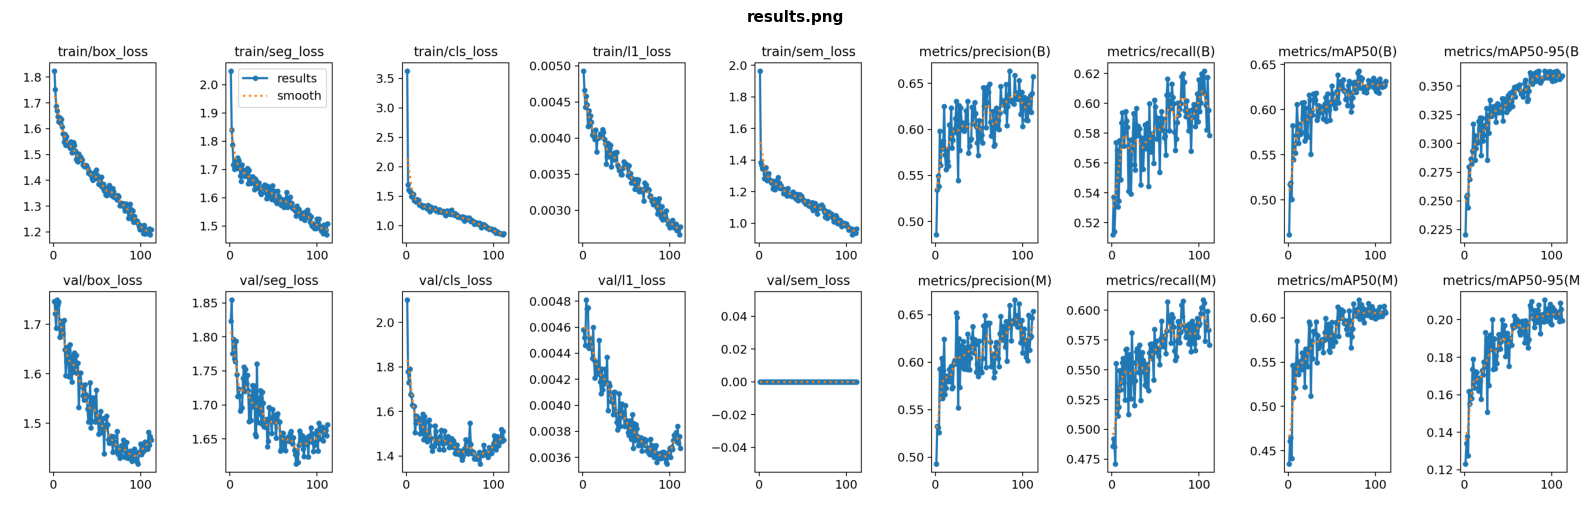


▶ Displaying Group: Bounding Box Localization Metrics
----------------------------------------------------------------------


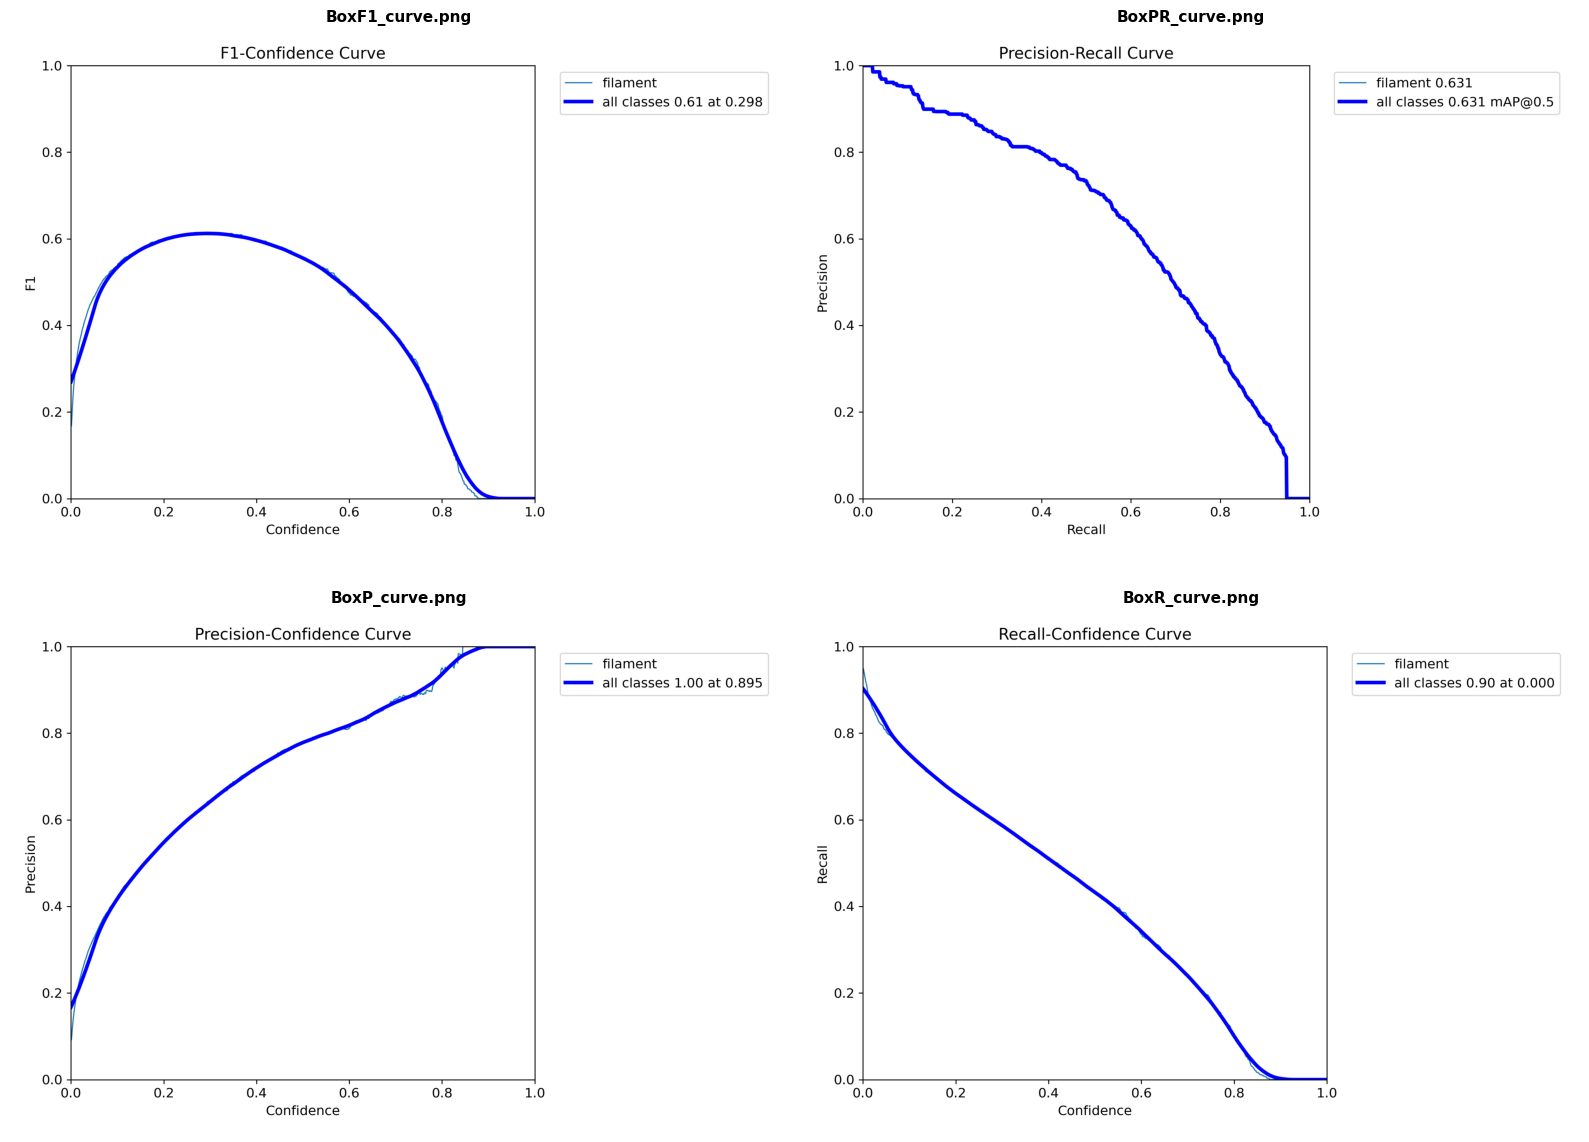


▶ Displaying Group: Instance Segmentation Mask Metrics
----------------------------------------------------------------------


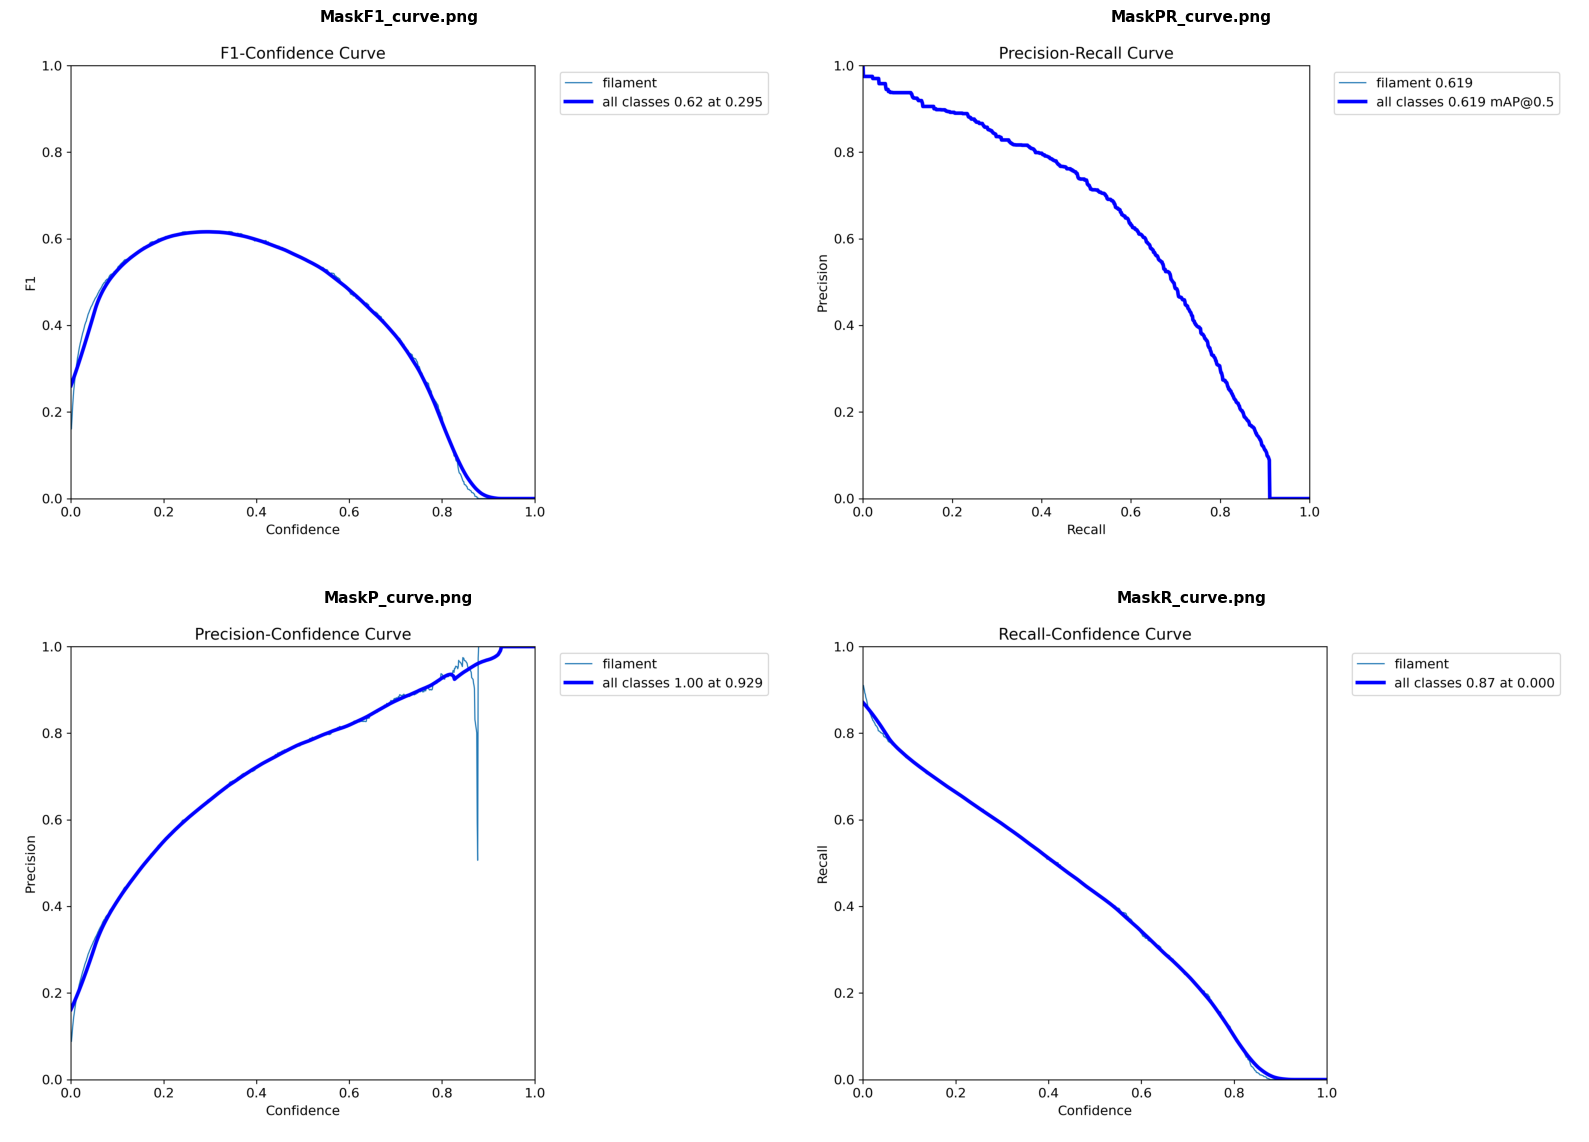


▶ Displaying Group: Confusion Matrices
----------------------------------------------------------------------


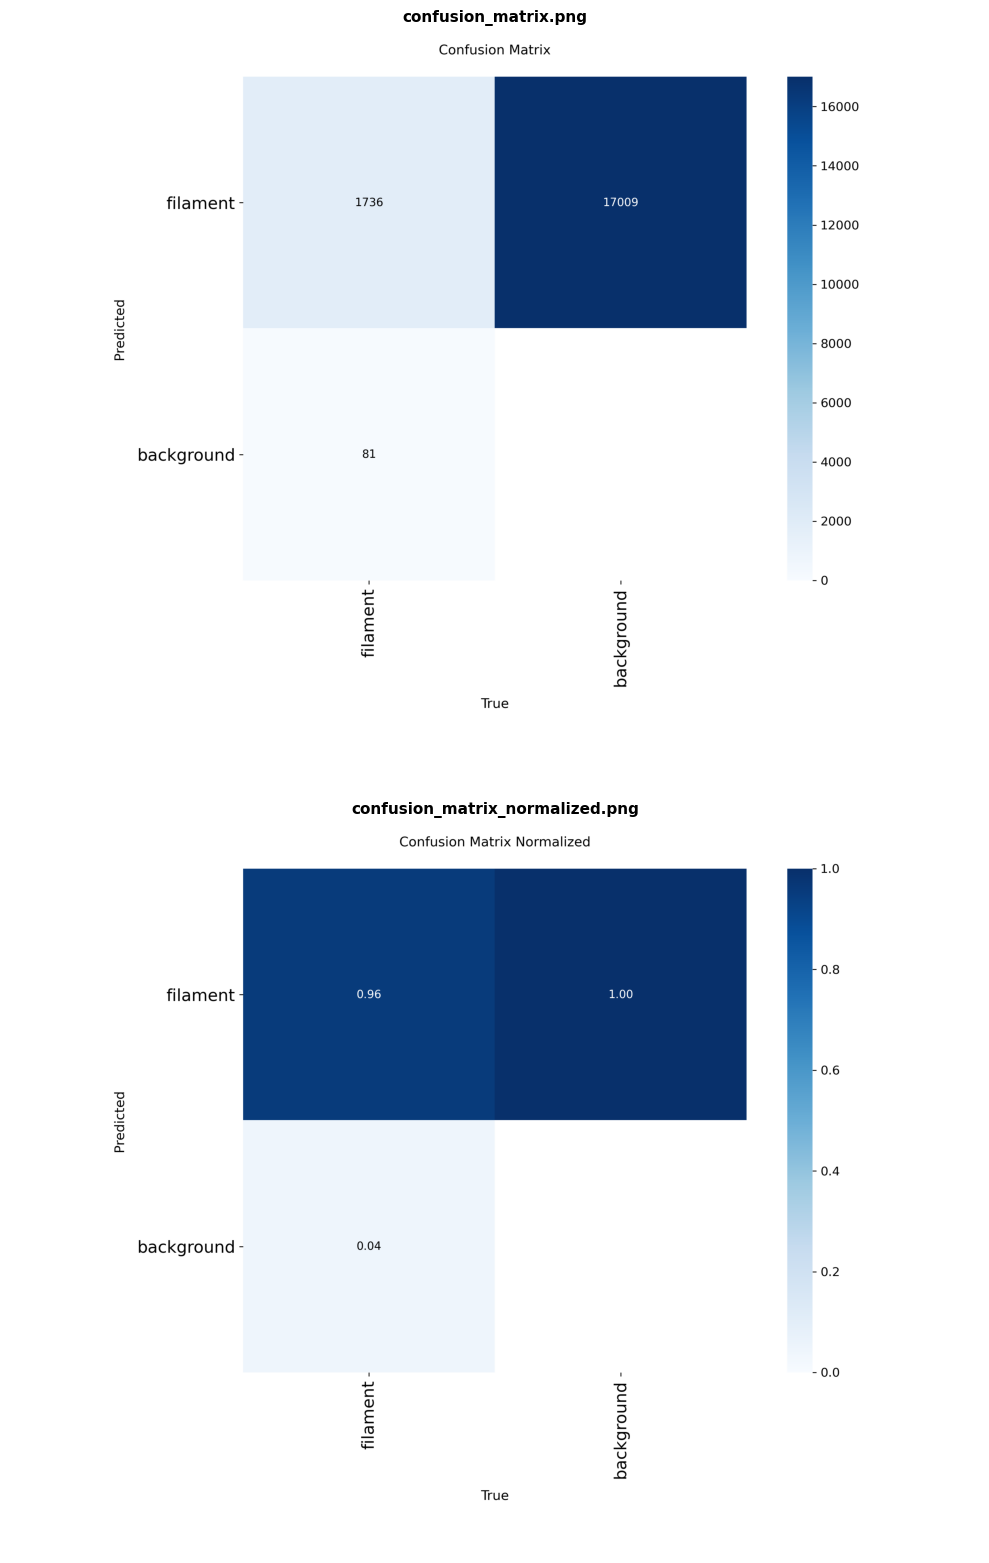


▶ Displaying Group: Labels
----------------------------------------------------------------------


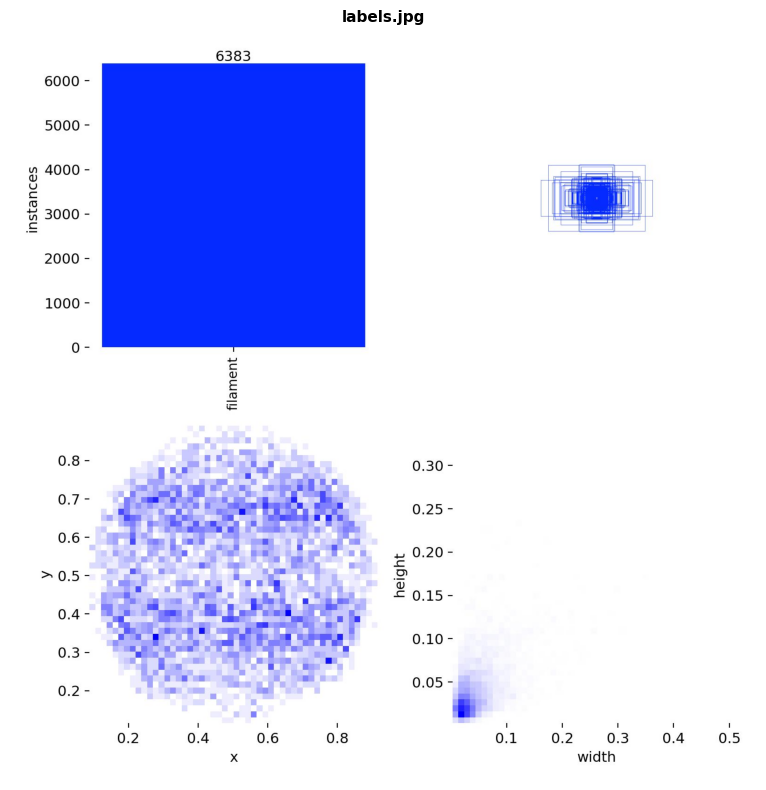


▶ Displaying Group: Training Dataset Batches & Anchors
----------------------------------------------------------------------


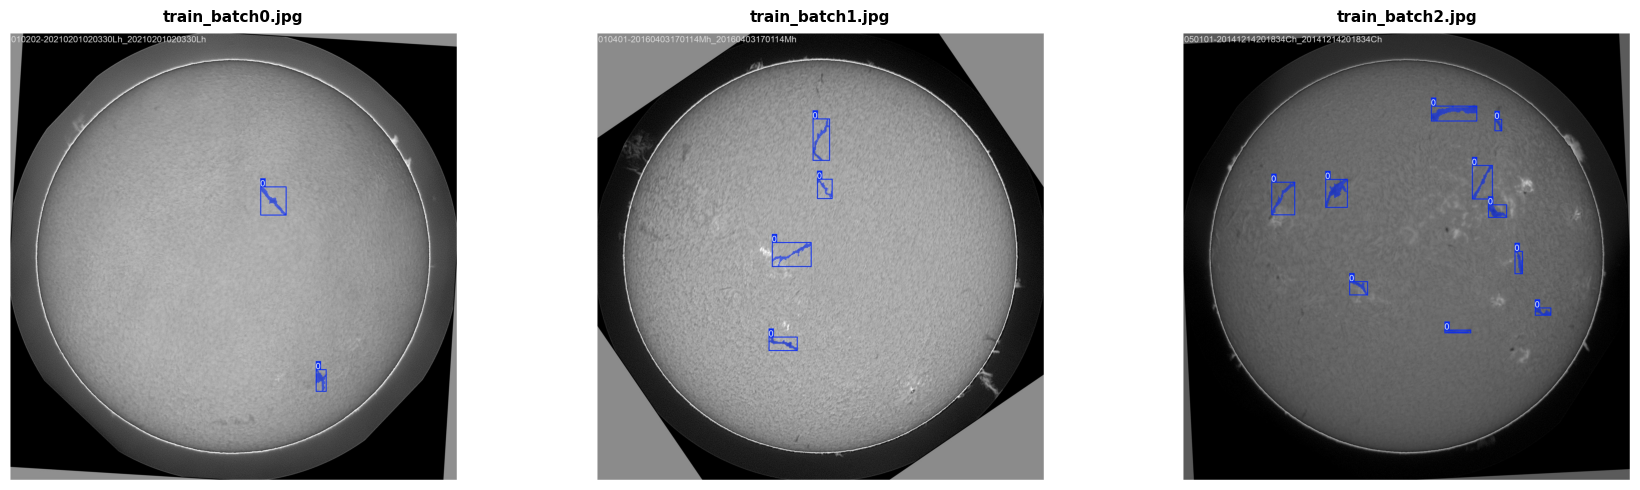


▶ Displaying Group: Validation Predictions vs Ground Truth
----------------------------------------------------------------------


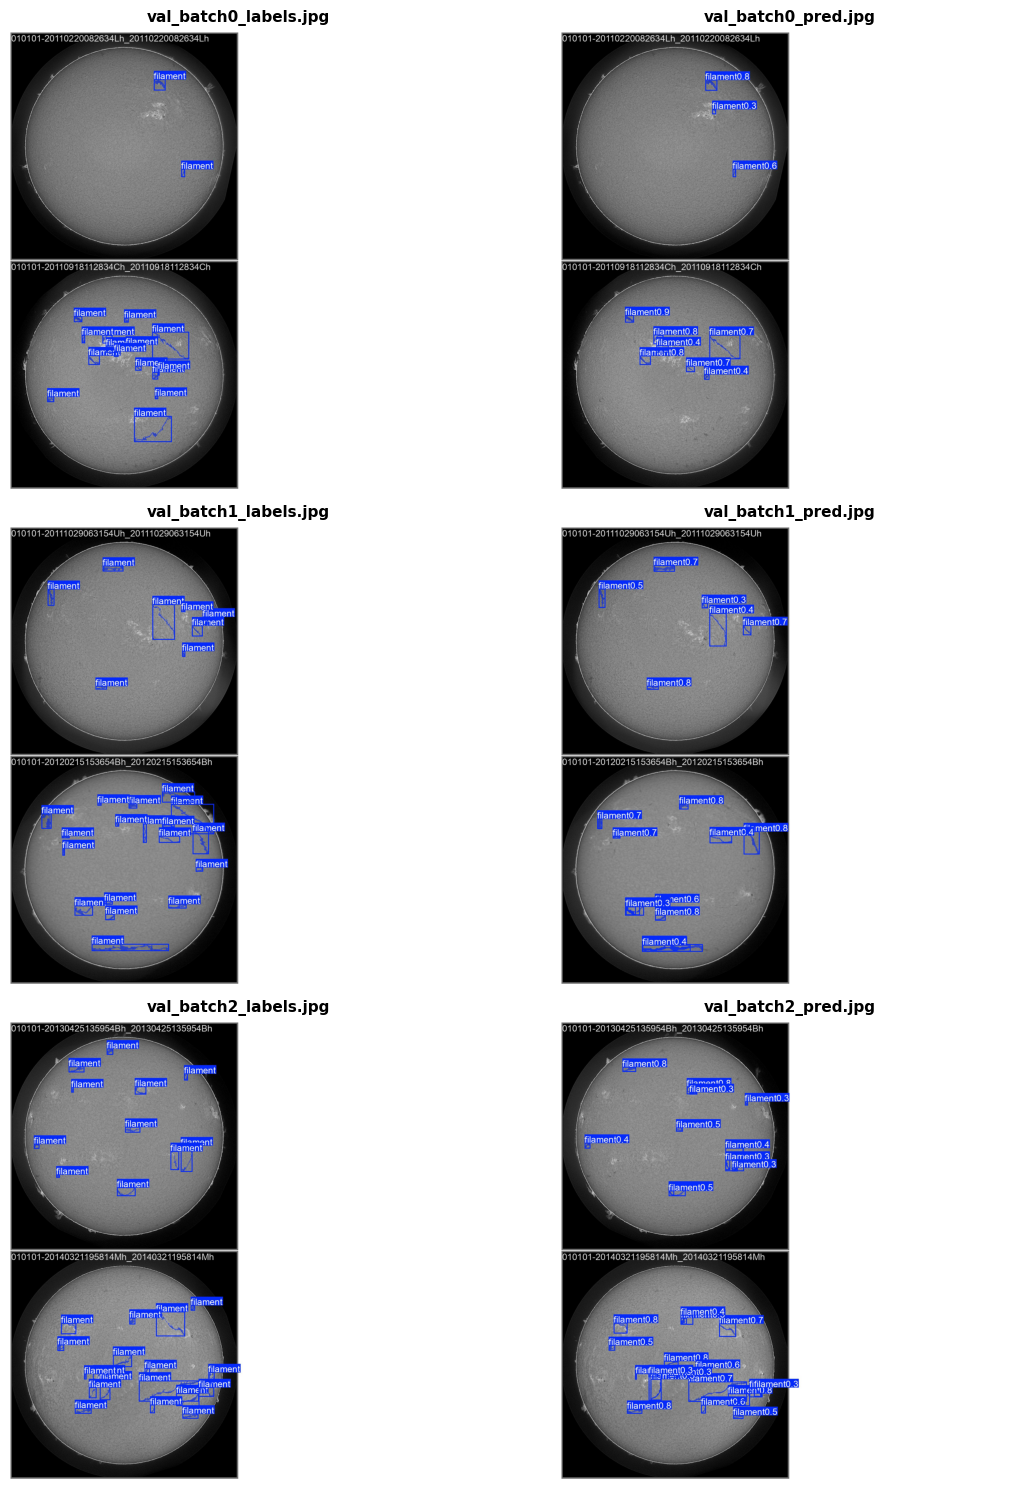

In [8]:
yolo_visual_groups = {
    "Overall Performance & Loss Tracking": [
        "results.png"
    ],
    "Bounding Box Localization Metrics": [
        "BoxF1_curve.png",
        "BoxPR_curve.png",
        "BoxP_curve.png",
        "BoxR_curve.png"
    ],
    "Instance Segmentation Mask Metrics": [
        "MaskF1_curve.png",
        "MaskPR_curve.png",
        "MaskP_curve.png",
        "MaskR_curve.png"
    ],
    "Confusion Matrices": [
        "confusion_matrix.png",
        "confusion_matrix_normalized.png"
    ],
    "Labels": [
        "labels.jpg"
    ],
    "Training Dataset Batches & Anchors": [
        "train_batch0.jpg",
        "train_batch1.jpg",
        "train_batch2.jpg"
    ],
    "Validation Predictions vs Ground Truth": [
        "val_batch0_labels.jpg",
        "val_batch0_pred.jpg",
        "val_batch1_labels.jpg",
        "val_batch1_pred.jpg",
        "val_batch2_labels.jpg",
        "val_batch2_pred.jpg"
    ]
}


display_settings = {
    "Overall Performance & Loss Tracking": {
        "cols": 1,
        "col_width": 16,
        "row_height": 9,
    },
    "Bounding Box Localization Metrics": {
        "cols": 2,
        "col_width": 8,
        "row_height": 6,
    },
    "Instance Segmentation Mask Metrics": {
        "cols": 2,
        "col_width": 8,
        "row_height": 6,
    },
    "Confusion Matrices": {
        "cols": 1,
        "col_width": 10,
        "row_height": 8,
    },
    "Labels": {
        "cols": 1,
        "col_width": 12,
        "row_height": 8,
    },
    "Training Dataset Batches & Anchors": {
        "cols": 3,
        "col_width": 6,
        "row_height": 5,
    },
    "Validation Predictions vs Ground Truth": {
        "cols": 2,
        "col_width": 6,
        "row_height": 5,
    },
}


print(
    f"Loading generated artifact visuals from: {run_dir}\n"
    + "=" * 70
)


for group_name, plot_files in yolo_visual_groups.items():
    valid_files = [
        f
        for f in plot_files
        if (run_dir / f).is_file()
    ]

    if not valid_files:
        continue

    print(f"\n▶ Displaying Group: {group_name}")
    print("-" * 70)

    settings = display_settings[group_name]

    cols = settings["cols"]
    col_width = settings["col_width"]
    row_height = settings["row_height"]

    num_plots = len(valid_files)
    num_rows = (num_plots + cols - 1) // cols

    fig, axes = plt.subplots(
        num_rows,
        cols,
        figsize=(
            col_width * cols,
            row_height * num_rows,
        ),
    )

    axes = np.atleast_1d(axes).flatten()

    for idx, plot_name in enumerate(valid_files):
        img = cv2.imread(str(run_dir / plot_name))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[idx].imshow(img)
        axes[idx].set_title(
            plot_name,
            fontsize=11,
            fontweight="bold",
            pad=8,
        )
        axes[idx].axis("off")

    for idx in range(num_plots, len(axes)):
        axes[idx].axis("off")

    fig.tight_layout()
    plt.show()

Available history columns:
epoch, time, train/box_loss, train/seg_loss, train/cls_loss, train/l1_loss, train/sem_loss, metrics/precision(B), metrics/recall(B), metrics/mAP50(B), metrics/mAP50-95(B), metrics/precision(M), metrics/recall(M), metrics/mAP50(M), metrics/mAP50-95(M), val/box_loss, val/seg_loss, val/cls_loss, val/l1_loss, val/sem_loss, lr/pg0, lr/pg1, lr/pg2


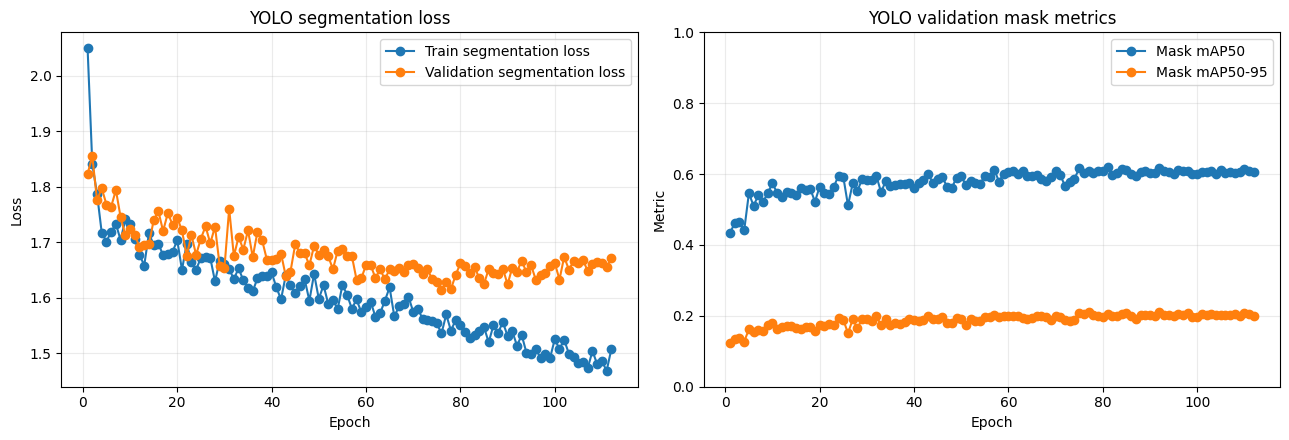

Best checkpoint: /kaggle/working/yolo_runs/yolo26s_filament_full_resolution/weights/best.pt


In [9]:
history_path = (
    run_dir / "results.csv"
)

if not history_path.is_file():
    raise FileNotFoundError(
        f"YOLO training history not found: "
        f"{history_path}"
    )

history = pd.read_csv(
    history_path
)

history.columns = [
    column.strip()
    for column in history.columns
]

print(
    "Available history columns:"
)

print(
    ", ".join(history.columns)
)

epochs = np.arange(
    1,
    len(history) + 1,
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 4.5),
)

for column, label in [
    (
        "train/seg_loss",
        "Train segmentation loss",
    ),
    (
        "val/seg_loss",
        "Validation segmentation loss",
    ),
]:
    if column in history.columns:
        axes[0].plot(
            epochs,
            history[column],
            marker="o",
            label=label,
        )

axes[0].set(
    title="YOLO segmentation loss",
    xlabel="Epoch",
    ylabel="Loss",
)

axes[0].legend()
axes[0].grid(alpha=0.25)

for column, label in [
    (
        "metrics/mAP50(M)",
        "Mask mAP50",
    ),
    (
        "metrics/mAP50-95(M)",
        "Mask mAP50-95",
    ),
]:
    if column in history.columns:
        axes[1].plot(
            epochs,
            history[column],
            marker="o",
            label=label,
        )

axes[1].set(
    title="YOLO validation mask metrics",
    xlabel="Epoch",
    ylabel="Metric",
    ylim=(0, 1),
)

axes[1].legend()
axes[1].grid(alpha=0.25)

fig.tight_layout()
plt.show()

print(
    f"Best checkpoint: "
    f"{best_checkpoint}"
)

## 7. Prediction and metric helpers

The prediction path is shared by validation and submission:

1. grayscale image → 3 identical pretrained-model channels
2. YOLO instance segmentation
3. confidence filtering
4. union of selected masks
5. connected-component splitting
6. evaluation or RLE encoding

In [10]:
def to_yolo_image(image):
    if image.ndim != 2:
        raise ValueError(f"Expected grayscale image, got shape {image.shape}")
    return cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

def get_test_image_paths():
    paths = [path for path in TEST_IMAGE_DIR.iterdir() if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg"}]
    return sorted(paths, key=lambda path: path.name)

def predict_instances_batch(images, min_confidence=0.15):
    sources = [to_yolo_image(image) for image in images]
    results = model.predict(
        source=sources, imgsz=IMAGE_SIZE, conf=min_confidence, iou=0.7, retina_masks=True,
        device=INFERENCE_DEVICE, batch=len(sources), max_det=MAX_DETECTIONS, verbose=False
    )
    outputs = []

    for image, result in zip(images, results):
        if result.masks is None or result.boxes is None:
            outputs.append([])
            continue

        masks = result.masks.data.detach().float().cpu().numpy()
        confidences = result.boxes.conf.detach().float().cpu().numpy()
        native_height, native_width = image.shape
        instances = []

        for mask, confidence in zip(masks, confidences):
            if mask.shape != image.shape:
                mask = cv2.resize(mask, (native_width, native_height), interpolation=cv2.INTER_NEAREST)
            instances.append({"mask": mask >= 0.5, "confidence": float(confidence)})
        outputs.append(instances)

    return outputs

def predict_instances(image, min_confidence=0.15):
    return predict_instances_batch([image], min_confidence=min_confidence)[0]

def union_instances(instances, confidence_threshold):
    selected = [instance for instance in instances if instance["confidence"] >= confidence_threshold]
    if not selected:
        return None

    foreground = np.zeros_like(selected[0]["mask"], dtype=bool)
    for instance in selected:
        foreground |= instance["mask"]
    return foreground

def split_into_filaments(binary_mask, min_area=MIN_COMPONENT_AREA):
    count, labels, stats, _ = cv2.connectedComponentsWithStats(binary_mask.astype(np.uint8), connectivity=8)
    components = []

    for label in range(1, count):
        area = int(stats[label, cv2.CC_STAT_AREA])
        if area < min_area:
            continue
        components.append(labels == label)

    def component_key(component):
        ys, xs = np.where(component)
        return (-int(component.sum()), int(ys.min()) if len(ys) else 0, int(xs.min()) if len(xs) else 0)

    return sorted(components, key=component_key)

def build_final_prediction_instances(instances, confidence_threshold):
    combined = union_instances(instances, confidence_threshold)
    if combined is None:
        return []
    return split_into_filaments(combined, MIN_COMPONENT_AREA)

def mask_to_rle(binary_mask):
    encoded = mask_utils.encode(np.asfortranarray(binary_mask.astype(np.uint8)))
    return encoded["counts"].decode("utf-8")


## 8. Full-resolution validation

Validation inference processes one 2048 x 2048 image at a time. Its asynchronous CPU queue is capped at eight tasks, and each metric worker uses one thread. This limits simultaneous full-resolution arrays while still overlapping GPU inference with CPU metrics.

In [11]:
dice_metric = DiceScore(num_classes=2, include_background=False, average="micro", input_format="index")

def calculate_pixel_metrics(prediction, target):
    prediction_tensor = torch.from_numpy(prediction.astype(np.int64)).unsqueeze(0)
    target_tensor = torch.from_numpy(target.astype(np.int64)).unsqueeze(0)

    prediction_has_foreground = bool(prediction.any())
    target_has_foreground = bool(target.any())

    if not prediction_has_foreground and not target_has_foreground:
        dice = 1.0
    else:
        dice = float(dice_metric(prediction_tensor, target_tensor).item())
        if np.isnan(dice):
            dice = 0.0

    intersection = int(np.logical_and(prediction, target).sum())
    union = int(np.logical_or(prediction, target).sum())
    true_positive = intersection

    false_positive = int(np.logical_and(prediction, ~target).sum())
    false_negative = int(np.logical_and(~prediction, target).sum())

    iou = intersection / union if union > 0 else 1.0
    precision_denominator = true_positive + false_positive
    recall_denominator = true_positive + false_negative

    precision = true_positive / precision_denominator if precision_denominator > 0 else 1.0
    recall = true_positive / recall_denominator if recall_denominator > 0 else 1.0

    return {
        "pixel_dice": float(dice),
        "pixel_iou": float(iou),
        "pixel_precision": float(precision),
        "pixel_recall": float(recall)
    }

def calculate_instance_metrics(prediction_instances, target_instances, iou_threshold=PQ_MATCH_IOU):
    num_predictions = len(prediction_instances)
    num_targets = len(target_instances)

    if num_predictions == 0 and num_targets == 0:
        return {"pq": 1.0, "sq": 1.0, "rq": 1.0, "tp_instances": 0, "fp_instances": 0, "fn_instances": 0, "one_to_many": 0, "many_to_one": 0, "matched_iou_sum": 0.0}
    if num_predictions == 0:
        return {"pq": 0.0, "sq": 0.0, "rq": 0.0, "tp_instances": 0, "fp_instances": 0, "fn_instances": num_targets, "one_to_many": 0, "many_to_one": 0, "matched_iou_sum": 0.0}
    if num_targets == 0:
        return {"pq": 0.0, "sq": 0.0, "rq": 0.0, "tp_instances": 0, "fp_instances": num_predictions, "fn_instances": 0, "one_to_many": 0, "many_to_one": 0, "matched_iou_sum": 0.0}

    iou_matrix = np.zeros((num_targets, num_predictions), dtype=np.float32)

    for gt_index, gt_mask in enumerate(target_instances):
        gt_area = int(gt_mask.sum())
        if gt_area == 0:
            continue
        for pred_index, pred_mask in enumerate(prediction_instances):
            pred_area = int(pred_mask.sum())
            if pred_area == 0:
                continue
            intersection = int(np.logical_and(gt_mask, pred_mask).sum())
            if intersection == 0:
                continue
            union = gt_area + pred_area - intersection
            iou_matrix[gt_index, pred_index] = intersection / union

    gt_relation_counts = (iou_matrix > iou_threshold).sum(axis=1)
    pred_relation_counts = (iou_matrix > iou_threshold).sum(axis=0)
    one_to_many = int((gt_relation_counts > 1).sum())
    many_to_one = int((pred_relation_counts > 1).sum())

    candidate_pairs = []
    for gt_index in range(num_targets):
        for pred_index in range(num_predictions):
            iou = float(iou_matrix[gt_index, pred_index])
            if iou > iou_threshold:
                candidate_pairs.append((iou, gt_index, pred_index))

    candidate_pairs.sort(key=lambda item: item[0], reverse=True)
    matched_gt, matched_predictions, matched_ious = set(), set(), []

    for iou, gt_index, pred_index in candidate_pairs:
        if gt_index in matched_gt or pred_index in matched_predictions:
            continue
        matched_gt.add(gt_index)
        matched_predictions.add(pred_index)
        matched_ious.append(iou)

    tp = len(matched_ious)
    fp = num_predictions - tp
    fn = num_targets - tp
    matched_iou_sum = float(np.sum(matched_ious))

    denominator = tp + 0.5 * fp + 0.5 * fn
    pq = matched_iou_sum / denominator if denominator > 0 else 0.0
    sq = matched_iou_sum / tp if tp > 0 else 0.0
    rq = tp / denominator if denominator > 0 else 0.0

    return {
        "pq": float(pq), "sq": float(sq), "rq": float(rq),
        "tp_instances": tp, "fp_instances": fp, "fn_instances": fn,
        "one_to_many": one_to_many, "many_to_one": many_to_one, "matched_iou_sum": matched_iou_sum
    }


In [12]:
def load_validation_images(rows):
    images, valid_rows = [], []
    for row in rows:
        image_path = TRAIN_IMAGE_DIR / row["file_name"]
        image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)
        if image is None:
            print(f"[WARNING] Could not read: {image_path}", flush=True)
            continue
        images.append(image)
        valid_rows.append(row)
    return valid_rows, images

def _worker_evaluate_validation_sample(task):
    configure_worker_process()
    global _local_val_coco

    if "_local_val_coco" not in globals():
        import sys
        old_stdout = sys.stdout
        sys.stdout = open(os.devnull, "w")
        _local_val_coco = COCO(task["annotation_path"])
        sys.stdout = old_stdout

    image_id = task["image_id"]
    file_name = task["file_name"]
    image_shape = tuple(task["image_shape"])
    polygons = task["polygons"]
    confidences = task["confidences"]

    target_instances = []
    annotation_ids = _local_val_coco.getAnnIds(imgIds=[image_id])
    annotations = _local_val_coco.loadAnns(annotation_ids)

    for annotation in annotations:
        mask = _local_val_coco.annToMask(annotation).astype(bool)
        if mask.any():
            target_instances.append(mask)

    target_union = np.zeros(image_shape, dtype=bool)
    for target_instance in target_instances:
        target_union |= target_instance

    outputs = {}
    for threshold in CONFIDENCE_CANDIDATES:
        prediction_union = np.zeros(image_shape, dtype=np.uint8)
        selected_predictions = 0

        for polygon, confidence in zip(polygons, confidences):
            if confidence < threshold:
                continue
            polygon = np.asarray(polygon, dtype=np.float32)
            if len(polygon) < 3:
                continue
            cv2.fillPoly(prediction_union, [np.round(polygon).astype(np.int32)], 1)
            selected_predictions += 1

        prediction_union = prediction_union.astype(bool)
        prediction_instances = split_into_filaments(prediction_union, MIN_COMPONENT_AREA)
        pixel_metrics = calculate_pixel_metrics(prediction_union, target_union)
        instance_metrics = calculate_instance_metrics(prediction_instances, target_instances)

        outputs[threshold] = {
            "file_name": file_name,
            "pixel_dice": pixel_metrics["pixel_dice"],
            "pixel_iou": pixel_metrics["pixel_iou"],
            "pixel_precision": pixel_metrics["pixel_precision"],
            "pixel_recall": pixel_metrics["pixel_recall"],
            "pq": instance_metrics["pq"],
            "sq": instance_metrics["sq"],
            "rq": instance_metrics["rq"],
            "tp_instances": instance_metrics["tp_instances"],
            "fp_instances": instance_metrics["fp_instances"],
            "fn_instances": instance_metrics["fn_instances"],
            "predicted_instances": len(prediction_instances),
            "ground_truth_instances": len(target_instances),
            "one_to_many": instance_metrics["one_to_many"],
            "many_to_one": instance_metrics["many_to_one"],
            "selected_predictions": selected_predictions
        }

    return outputs

In [13]:
# Force garbage collection before allocating validation arrays
gc.collect()

require_ram_headroom("validation", minimum_gib=RAM_RESERVE_GIB + 2.0)
validation_start = time.perf_counter()

minimum_confidence = min(CONFIDENCE_CANDIDATES)

validation_examples = []

threshold_results = {
    threshold: {"per_image": []}
    for threshold in CONFIDENCE_CANDIDATES
}

val_rows = val_records[["image_id", "file_name"]].to_dict(orient="records")

total_validation_records = len(val_rows)

print("\n" + "=" * 90)
print("                 PARALLEL VALIDATION")
print("=" * 90)
print(f"Validation records : {total_validation_records:,}")
print(f"CPU workers        : {NUM_WORKERS}")
print(f"Target aggregate CPU usage: ~{NUM_WORKERS * 100}%")
print(f"GPU batch size     : {VAL_BATCH_SIZE}")
print("CPU workload       : polygon rasterization + connected components + metrics")
print("=" * 90, flush=True)

# Persistent CPU pool.
pool = multiprocessing.Pool(
    processes=NUM_WORKERS,
    initializer=configure_worker_process,
)

pending = []

try:
    for batch_start in range(0, total_validation_records, VAL_BATCH_SIZE):
        batch_rows = val_rows[batch_start:batch_start + VAL_BATCH_SIZE]

        loaded_rows, images = load_validation_images(batch_rows)

        if not images:
            continue

        # ------------------------------------------------------
        # GPU inference in batches.
        # ------------------------------------------------------

        batch_instances = predict_instances_batch(
            images,
            min_confidence=minimum_confidence,
        )

        # ------------------------------------------------------
        # Submit CPU evaluation asynchronously.
        # ------------------------------------------------------

        for row, image, instances in zip(loaded_rows, images, batch_instances):
            polygons = []
            confidences = []

            for instance in instances:
                mask = instance["mask"]

                contours, _ = cv2.findContours(
                    mask.astype(np.uint8),
                    cv2.RETR_EXTERNAL,
                    cv2.CHAIN_APPROX_SIMPLE,
                )

                if not contours:
                    continue

                contour = max(contours, key=cv2.contourArea)

                if len(contour) < 3:
                    continue

                polygon = contour.reshape(-1, 2).astype(np.float32)

                polygons.append(polygon)
                confidences.append(float(instance["confidence"]))

            task = {
                "annotation_path": str(ANNOTATION_PATH),
                "image_id": row["image_id"],
                "file_name": row["file_name"],
                "image_shape": image.shape,
                "polygons": polygons,
                "confidences": confidences,
            }

            pending.append(
                pool.apply_async(
                    _worker_evaluate_validation_sample,
                    (task,),
                )
            )

            if len(pending) >= MAX_PENDING_VALIDATION:
                result = pending.pop(0).get()

                for threshold in CONFIDENCE_CANDIDATES:
                    threshold_results[threshold]["per_image"].append(
                        result[threshold]
                    )

        # ------------------------------------------------------
        # Save a few examples for visualization.
        # ------------------------------------------------------

        # Save exactly 4 isolated examples for visualization without holding array references
        if len(validation_examples) < 4:
            for row, image, instances in zip(loaded_rows, images, batch_instances):
                if len(validation_examples) >= 4:
                    break

                annotations = coco.loadAnns(coco.getAnnIds(imgIds=[row["image_id"]]))
                target = np.zeros(image.shape, dtype=bool)

                for annotation in annotations:
                    target |= coco.annToMask(annotation).astype(bool)

                # Store detached copies to break cross-reference locks
                validation_examples.append(
                    {
                        "image": image.copy(),
                        "target": target.copy(),
                        "instances": [{k: (v.copy() if isinstance(v, np.ndarray) else v) for k, v in inst.items()} for inst in instances],
                        "file_name": row["file_name"],
                    }
                )

        processed = min(
            batch_start + len(loaded_rows),
            total_validation_records,
        )

        print(
            f"{processed:,}/{total_validation_records:,} records | "
            f"pending CPU jobs: {len(pending)}",
            flush=True,
        )

        try:
            del loaded_rows, images, batch_instances, polygons, confidences, task
        except NameError:
            pass
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    print(
        "\n[CPU] Draining remaining validation workers...",
        flush=True,
    )

    while pending:
        result = pending.pop(0).get()

        for threshold in CONFIDENCE_CANDIDATES:
            threshold_results[threshold]["per_image"].append(
                result[threshold]
            )

finally:
    pool.close()
    pool.join()

validation_time = time.perf_counter() - validation_start

threshold_rows = []

for threshold in CONFIDENCE_CANDIDATES:
    per_image_df = pd.DataFrame(
        threshold_results[threshold]["per_image"]
    )

    if per_image_df.empty:
        continue

    threshold_rows.append(
        {
            "confidence": threshold,
            "PQ": per_image_df["pq"].mean(),
            "SQ": per_image_df["sq"].mean(),
            "RQ": per_image_df["rq"].mean(),
            "Mean Dice": per_image_df["pixel_dice"].mean(),
            "Mean IoU": per_image_df["pixel_iou"].mean(),
            "Mean Precision": per_image_df["pixel_precision"].mean(),
            "Mean Recall": per_image_df["pixel_recall"].mean(),
            "TP": int(per_image_df["tp_instances"].sum()),
            "FP": int(per_image_df["fp_instances"].sum()),
            "FN": int(per_image_df["fn_instances"].sum()),
            "Predicted Instances": int(
                per_image_df["predicted_instances"].sum()
            ),
            "GT Instances": int(
                per_image_df["ground_truth_instances"].sum()
            ),
            "One-to-Many": int(per_image_df["one_to_many"].sum()),
            "Many-to-One": int(per_image_df["many_to_one"].sum()),
        }
    )

threshold_summary = (
    pd.DataFrame(threshold_rows)
    .sort_values("PQ", ascending=False)
    .reset_index(drop=True)
)

BEST_CONFIDENCE = float(threshold_summary.iloc[0]["confidence"])

print("\n" + "=" * 100)
print("                    VALIDATION RESULTS")
print("=" * 100)

display(threshold_summary.round(4))

print(f"\nSelected confidence threshold: {BEST_CONFIDENCE:.2f}")
print(f"Best validation PQ: {threshold_summary.iloc[0]['PQ']:.4f}")
print(f"Validation time: {validation_time:.1f}s")

print("=" * 100, flush=True)

[RAM] Available before validation: 15.3 GiB

                 PARALLEL VALIDATION
Validation records : 232
CPU workers        : 4
Target aggregate CPU usage: ~400%
GPU batch size     : 1
CPU workload       : polygon rasterization + connected components + metrics
1/232 records | pending CPU jobs: 1
2/232 records | pending CPU jobs: 2
3/232 records | pending CPU jobs: 3
4/232 records | pending CPU jobs: 4
5/232 records | pending CPU jobs: 5
6/232 records | pending CPU jobs: 6
7/232 records | pending CPU jobs: 7
8/232 records | pending CPU jobs: 7
9/232 records | pending CPU jobs: 7
10/232 records | pending CPU jobs: 7
11/232 records | pending CPU jobs: 7
12/232 records | pending CPU jobs: 7
13/232 records | pending CPU jobs: 7
14/232 records | pending CPU jobs: 7
15/232 records | pending CPU jobs: 7
16/232 records | pending CPU jobs: 7
17/232 records | pending CPU jobs: 7
18/232 records | pending CPU jobs: 7
19/232 records | pending CPU jobs: 7
20/232 records | pending CPU jobs: 7
21/232

,confidence,PQ,SQ,RQ,Mean Dice,Mean IoU,Mean Precision,Mean Recall,TP,FP,FN,Predicted Instances,GT Instances,One-to-Many,Many-to-One
0,0.25,0.4221,0.6468,0.6268,0.6564,0.5049,0.7216,0.6607,1093,520,724,1613,1817,0,1
1,0.15,0.4191,0.6521,0.6231,0.6637,0.5102,0.6793,0.7068,1171,721,646,1892,1817,0,1
2,0.35,0.4156,0.6453,0.6158,0.6397,0.4882,0.7499,0.6120,987,350,830,1337,1817,0,1
3,0.45,0.3846,0.6336,0.5649,0.5970,0.4494,0.7747,0.5437,859,258,958,1117,1817,0,1
4,0.55,0.3418,0.6248,0.4972,0.5293,0.3866,0.7891,0.4546,696,169,1121,865,1817,0,1



Selected confidence threshold: 0.25
Best validation PQ: 0.4221
Validation time: 850.3s


## 9. Generate the competition submission

Test inference runs one native-resolution image at a time. CPU connected-component extraction and RLE encoding use at most four single-threaded workers, and rows are written incrementally to the CSV.

In [14]:
import queue

def _submission_worker_optimized(task, result_queue):
    """
    Worker process target. Processes the mask and pushes rows 
    straight to a thread-safe queue to avoid main-thread stalling.
    """
    combined_mask = task["combined_mask"]
    path_stem = task["path_stem"]
    components = split_into_filaments(combined_mask, MIN_COMPONENT_AREA)

    rows = []
    for filament_counter, component in enumerate(components, start=1):
        rows.append((f"{path_stem}_{filament_counter}", mask_to_rle(component)))
    
    # Push the result back to the main thread
    result_queue.put(rows)

def create_submission_parallel(output_path=SUBMISSION_PATH):
    paths = get_test_image_paths()
    if not paths:
        raise FileNotFoundError(f"No .jpg/.jpeg images found in {TEST_IMAGE_DIR}")

    require_ram_headroom("submission inference", minimum_gib=RAM_RESERVE_GIB + 2.0)
    total_images = len(paths)
    start_time = time.perf_counter()

    print(f"[START] Test images: {total_images:,}\n[CONFIG] GPU batch: {VAL_BATCH_SIZE}\n[CONFIG] CPU workers: {NUM_WORKERS}", flush=True)
    
    # Use a Manager to create a thread/process-safe Queue
    manager = multiprocessing.Manager()
    result_queue = manager.Queue()
    
    cpu_pool = multiprocessing.Pool(processes=NUM_WORKERS, initializer=configure_worker_process)

    with open(output_path, mode='w', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        writer.writerow(["filament_id", "segmentation_rle"])

        total_rows_written = 0
        tasks_submitted = 0
        tasks_resolved = 0
        seen_filament_ids = set()

        try:
            for batch_start in range(0, total_images, VAL_BATCH_SIZE):
                batch_paths = paths[batch_start:batch_start + VAL_BATCH_SIZE]
                images = []

                for path in batch_paths:
                    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
                    if image is None:
                        raise OSError(f"Could not read test image: {path}")
                    images.append(image)

                # Heavy GPU inference step
                batch_instances = predict_instances_batch(images, min_confidence=BEST_CONFIDENCE)

                for path, image, instances in zip(batch_paths, images, batch_instances):
                    combined = union_instances(instances, BEST_CONFIDENCE)
                    if combined is None:
                        combined = np.zeros(image.shape, dtype=bool)

                    # Dispatch to pool completely asynchronously
                    cpu_pool.apply_async(
                        _submission_worker_optimized, 
                        args=({"combined_mask": combined, "path_stem": path.stem}, result_queue)
                    )
                    tasks_submitted += 1

                # Flush out whatever CPU work has finished up to this point WITHOUT blocking
                while True:
                    try:
                        worker_rows = result_queue.get_nowait()
                        for fid, rle in worker_rows:
                            if fid in seen_filament_ids:
                                raise ValueError(f"Duplicate filament ID detected: {fid}")
                            seen_filament_ids.add(fid)
                            writer.writerow([fid, rle])
                            total_rows_written += 1
                        tasks_resolved += 1
                    except queue.Empty:
                        break # No more completed tasks at this exact millisecond

                processed = min(batch_start + len(batch_paths), total_images)
                print(f"Inference Progress: {processed:,}/{total_images:,} | Active CPU Tasks: {tasks_submitted - tasks_resolved}", flush=True)
                
                del images, batch_instances
                gc.collect()

            # Clean up the pool so workers don't accept new tasks
            cpu_pool.close()
            
            # Block and drain the remaining finished items out of the queue
            print("\nFinishing remaining CPU post-processing tasks...", flush=True)
            while tasks_resolved < tasks_submitted:
                worker_rows = result_queue.get() # Blocking get is safe here because pool is closing
                for fid, rle in worker_rows:
                    if fid in seen_filament_ids:
                        raise ValueError(f"Duplicate filament ID detected: {fid}")
                    seen_filament_ids.add(fid)
                    writer.writerow([fid, rle])
                    total_rows_written += 1
                tasks_resolved += 1

            cpu_pool.join()

        finally:
            # Safeguard to ensure pool terminates if an exception throws early
            cpu_pool.close()
            cpu_pool.terminate()
            cpu_pool.join()

    elapsed = time.perf_counter() - start_time
    print(f"\n[SUCCESS] Submission complete!\nProcessed: {total_images:,} images\nFilament rows written: {total_rows_written:,}\nRuntime: {elapsed / 60:.2f} min\nSaved: {output_path}", flush=True)
    return pd.read_csv(output_path, nrows=5) if total_rows_written > 0 else None


## 10. Submission audit and final validation report

In [15]:
if CREATE_SUBMISSION:
    create_submission_parallel()
    
    audit_columns = None
    audit_row_count = 0
    audit_null_count = 0
    duplicate_ids = 0
    empty_rle_count = 0
    seen_ids = set()
    sample_rle_valid = False

    

    with open(SUBMISSION_PATH, newline="", encoding="utf-8") as audit_file:
        reader = csv.DictReader(audit_file)
        audit_columns = reader.fieldnames
        for row in reader:
            audit_row_count += 1
            if audit_row_count == 1:
                sample_rle_valid = bool(row.get("segmentation_rle"))

            if any(value is None for value in row.values()):
                audit_null_count += 1

            filament_id = row.get("filament_id")
            rle = row.get("segmentation_rle")
            if not filament_id or not rle:
                empty_rle_count += 1
            if filament_id in seen_ids:
                duplicate_ids += 1
            elif filament_id:
                seen_ids.add(filament_id)
else:
    audit_columns = ["filament_id", "segmentation_rle"]
    audit_row_count = 0
    audit_null_count = 0
    duplicate_ids = 0
    empty_rle_count = 0
    sample_rle_valid = False

print("--- Submission File Integrity Audit (streamed) ---")
print(f"Total rows: {audit_row_count:,}")
print(f"Null values: {audit_null_count:,}")
print(f"Duplicate filament IDs: {duplicate_ids:,}")
print(f"Empty IDs/RLE strings: {empty_rle_count:,}")
print(f"Sample RLE check: {sample_rle_valid}")

submission_valid = (
    set(audit_columns or []) == {"filament_id", "segmentation_rle"}
    and audit_null_count == 0
    and duplicate_ids == 0
    and empty_rle_count == 0
    and (sample_rle_valid or audit_row_count == 0)
)

print("\n" + ("[VERIFIED] Submission structure passed the local audit." if submission_valid else "[WARNING] Submission structure needs inspection."))

best_row = threshold_summary[threshold_summary["confidence"] == BEST_CONFIDENCE].iloc[0]

final_metrics = pd.DataFrame(
    {
        "Metric": [
            "Panoptic Quality (PQ)", "Segmentation Quality (SQ)",
            "Recognition Quality (RQ)", "Mean Dice", "Mean IoU",
            "Mean Precision", "Mean Recall", "True Positives",
            "False Positives", "False Negatives", "Predicted Instances",
            "Ground-Truth Instances", "One-to-Many (Fragmentation)",
            "Many-to-One (Over-Merging)", "Selected Confidence",
        ],
        "Value": [
            best_row["PQ"], best_row["SQ"], best_row["RQ"],
            best_row["Mean Dice"], best_row["Mean IoU"],
            best_row["Mean Precision"], best_row["Mean Recall"],
            int(best_row["TP"]), int(best_row["FP"]), int(best_row["FN"]),
            int(best_row["Predicted Instances"]), int(best_row["GT Instances"]),
            int(best_row["One-to-Many"]), int(best_row["Many-to-One"]),
            BEST_CONFIDENCE,
        ],
    }
)

print("\n" + "=" * 75)
print("                 FINAL VALIDATION REPORT")
print("=" * 75)
display(final_metrics.round(4))

selected_per_image = pd.DataFrame(threshold_results[BEST_CONFIDENCE]["per_image"])
distribution = (
    selected_per_image[["pixel_dice", "pixel_iou", "pq", "sq", "rq"]]
    .agg(["mean", "median", "std", "min", "max"])
    .T
)
print("\n--- Per-image metric distribution ---")
display(distribution.round(4))

best_mask_map50 = (
    float(history["metrics/mAP50(M)"].max())
    if "metrics/mAP50(M)" in history.columns else np.nan
)
best_mask_map50_95 = (
    float(history["metrics/mAP50-95(M)"].max())
    if "metrics/mAP50-95(M)" in history.columns else np.nan
)

diagnostics = pd.DataFrame(
    {
        "Diagnostic": [
            "YOLO best mask mAP50", "YOLO best mask mAP50-95",
            "Validation records", "Submission rows", "Submission valid",
        ],
        "Value": [
            best_mask_map50, best_mask_map50_95,
            len(selected_per_image), audit_row_count, submission_valid,
        ],
    }
)
print("\n--- Model / submission diagnostics ---")
display(diagnostics)

final_metrics.to_csv(FINAL_METRICS_PATH, index=False)
selected_per_image.to_csv(PER_IMAGE_METRICS_PATH, index=False)
print(f"Saved validation summary: {FINAL_METRICS_PATH}")
print(f"Saved per-image metrics: {PER_IMAGE_METRICS_PATH}")

[RAM] Available before submission inference: 14.7 GiB
[START] Test images: 180
[CONFIG] GPU batch: 1
[CONFIG] CPU workers: 4
Inference Progress: 1/180 | Active CPU Tasks: 1
Inference Progress: 2/180 | Active CPU Tasks: 1
Inference Progress: 3/180 | Active CPU Tasks: 1
Inference Progress: 4/180 | Active CPU Tasks: 1
Inference Progress: 5/180 | Active CPU Tasks: 1
Inference Progress: 6/180 | Active CPU Tasks: 1
Inference Progress: 7/180 | Active CPU Tasks: 1
Inference Progress: 8/180 | Active CPU Tasks: 1
Inference Progress: 9/180 | Active CPU Tasks: 1
Inference Progress: 10/180 | Active CPU Tasks: 1
Inference Progress: 11/180 | Active CPU Tasks: 1
Inference Progress: 12/180 | Active CPU Tasks: 1
Inference Progress: 13/180 | Active CPU Tasks: 1
Inference Progress: 14/180 | Active CPU Tasks: 1
Inference Progress: 15/180 | Active CPU Tasks: 1
Inference Progress: 16/180 | Active CPU Tasks: 1
Inference Progress: 17/180 | Active CPU Tasks: 1
Inference Progress: 18/180 | Active CPU Tasks: 1
In

,Metric,Value
0,Panoptic Quality (PQ),0.4221
1,Segmentation Quality (SQ),0.6468
2,Recognition Quality (RQ),0.6268
3,Mean Dice,0.6564
4,Mean IoU,0.5049
5,Mean Precision,0.7216
6,Mean Recall,0.6607
7,True Positives,1093.0000
8,False Positives,520.0000
9,False Negatives,724.0000



--- Per-image metric distribution ---


,mean,median,std,min,max
pixel_dice,0.6564,0.6885,0.1544,0.0,0.8852
pixel_iou,0.5049,0.5250,0.1454,0.0,0.7941
pq,0.4221,0.4340,0.1510,0.0,0.7628
sq,0.6468,0.6731,0.1388,0.0,0.8115
rq,0.6268,0.6667,0.2196,0.0,1.0000



--- Model / submission diagnostics ---


,Diagnostic,Value
0,YOLO best mask mAP50,0.62029
1,YOLO best mask mAP50-95,0.21055
2,Validation records,232
3,Submission rows,1211
4,Submission valid,True


Saved validation summary: /kaggle/working/solar_filament_yolo26s_validation_metrics.csv
Saved per-image metrics: /kaggle/working/solar_filament_yolo26s_per_image_metrics.csv


## 11. Threshold visualization and validation examples

Threshold selection is based on **PQ**.

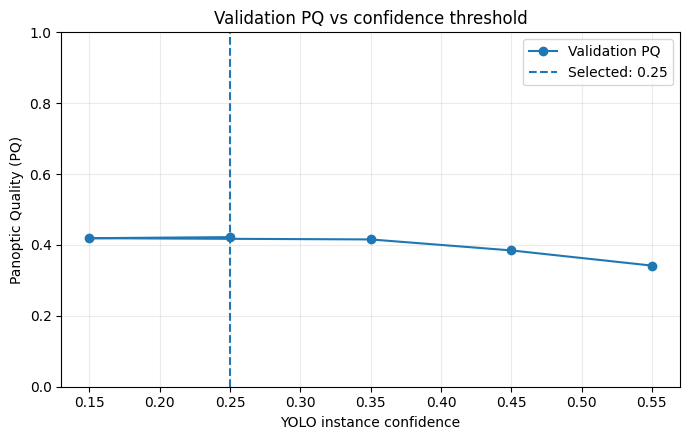

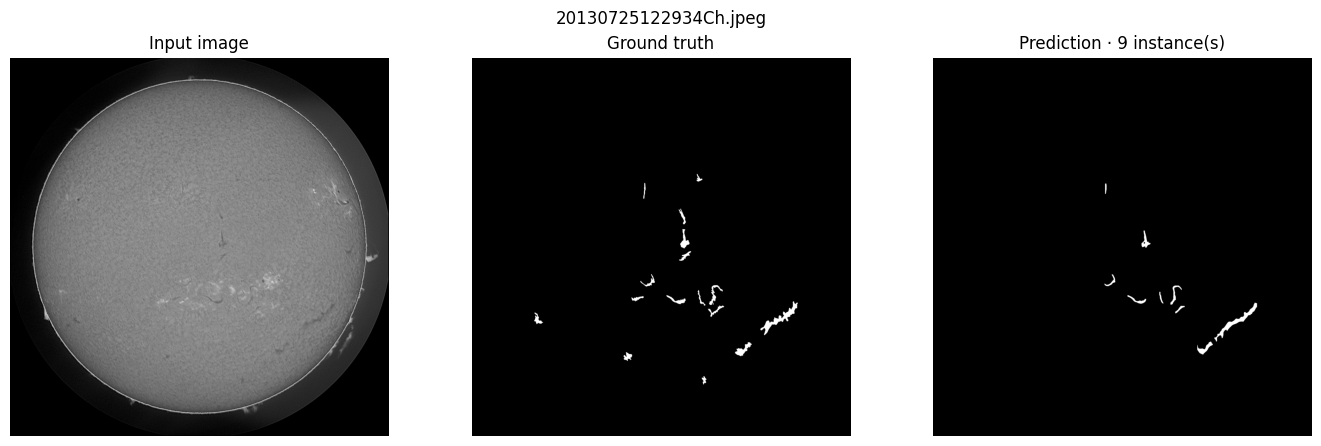

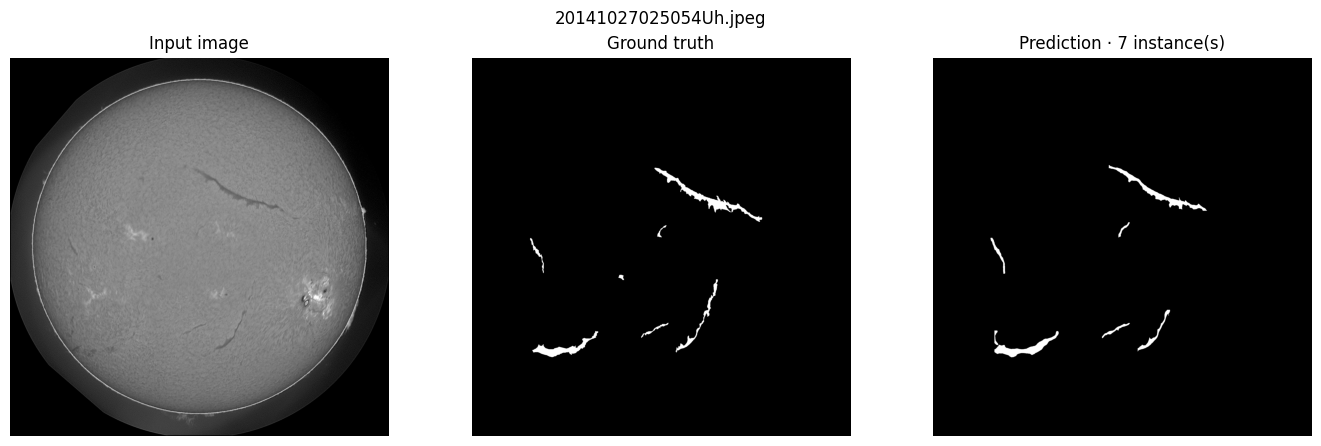

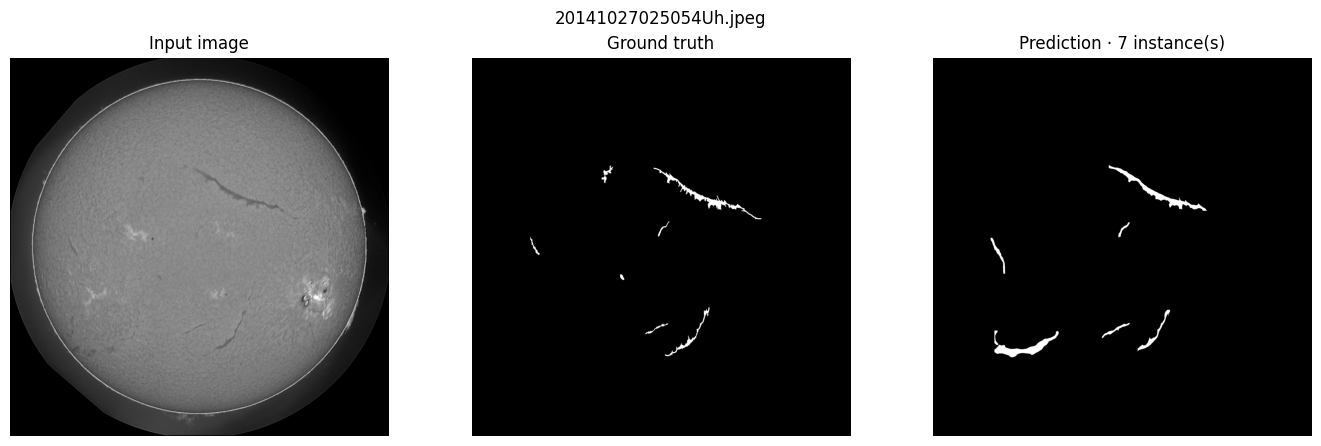

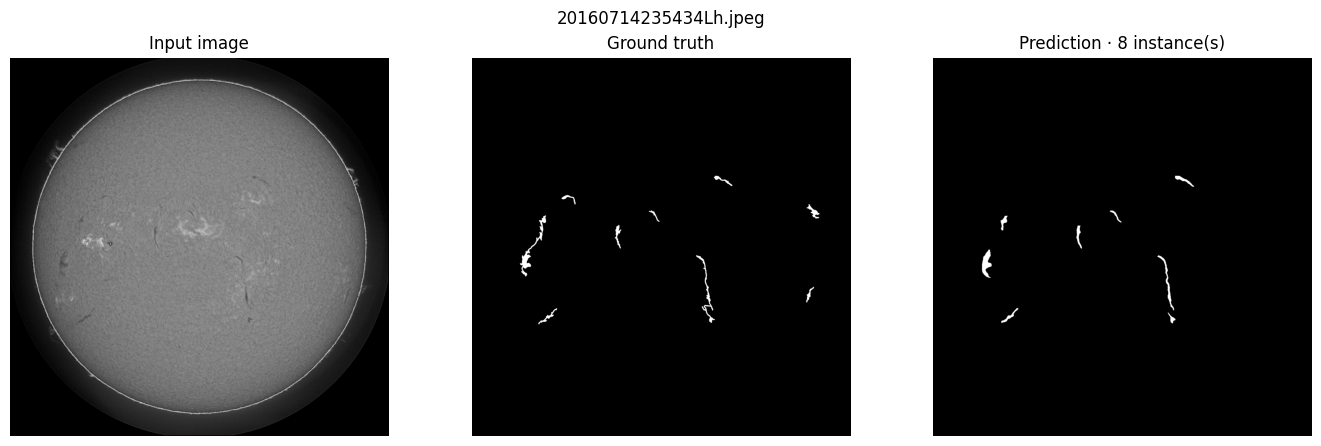

In [16]:
fig, axis = plt.subplots(figsize=(7, 4.5))
axis.plot(threshold_summary["confidence"], threshold_summary["PQ"], marker="o", label="Validation PQ")
axis.axvline(BEST_CONFIDENCE, linestyle="--", label=f"Selected: {BEST_CONFIDENCE:.2f}")
axis.set(title="Validation PQ vs confidence threshold", xlabel="YOLO instance confidence", ylabel="Panoptic Quality (PQ)", ylim=(0, 1))
axis.grid(alpha=0.25)
axis.legend()
fig.tight_layout()
plt.show()

for example in validation_examples:
    image = example["image"]
    target = example["target"]
    instances = example["instances"]

    prediction = union_instances(instances, BEST_CONFIDENCE)
    if prediction is None:
        prediction = np.zeros_like(target, dtype=bool)

    selected_prediction_instances = build_final_prediction_instances(instances, BEST_CONFIDENCE)

    fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
    axes[0].imshow(image, cmap="gray")
    axes[0].set_title("Input image")
    axes[1].imshow(target, cmap="gray", vmin=0, vmax=1)
    axes[1].set_title("Ground truth")
    axes[2].imshow(prediction, cmap="gray", vmin=0, vmax=1)
    axes[2].set_title(f"Prediction · {len(selected_prediction_instances)} instance(s)")

    for axis in axes:
        axis.axis("off")

    fig.suptitle(example["file_name"])
    fig.tight_layout()
    plt.show()


## 12. Display a labeled prediction on an unseen test image

The test image is used only for inference/visualization. No test ground truth is accessed.

Displaying labeled prediction for test image: 20110120105534Ch.jpeg


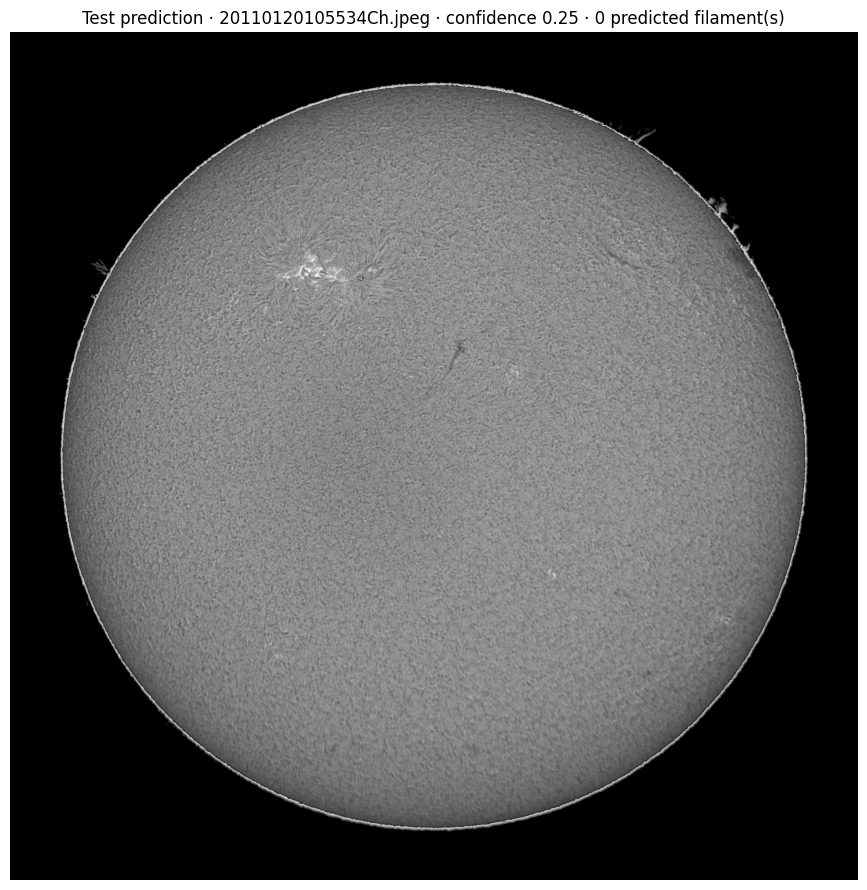

In [17]:
def plot_labeled_prediction(image, instances, title):
    combined = union_instances(instances, BEST_CONFIDENCE)
    components = split_into_filaments(combined) if combined is not None else []

    fig, axis = plt.subplots(figsize=(9, 9))
    axis.imshow(image, cmap="gray")

    for filament_index, component in enumerate(components, start=1):
        axis.contour(component.astype(np.uint8), levels=[0.5], linewidths=1.2)
        moments = cv2.moments(component.astype(np.uint8))

        if moments["m00"]:
            center_x = moments["m10"] / moments["m00"]
            center_y = moments["m01"] / moments["m00"]
        else:
            ys, xs = np.where(component)
            center_x, center_y = xs.mean(), ys.mean()

        area = int(component.sum())
        axis.text(
            center_x, center_y, f"F{filament_index}\n{area:,} px", fontsize=8, ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.75)
        )

    axis.set_title(f"{title} · {len(components)} predicted filament(s)")
    axis.axis("off")
    fig.tight_layout()
    plt.show()

test_paths = get_test_image_paths()
if not test_paths:
    raise FileNotFoundError("No test images were found.")

test_path = test_paths[0]
test_image = cv2.imread(str(test_path), cv2.IMREAD_GRAYSCALE)
if test_image is None:
    raise OSError(f"Could not read test image: {test_path}")

test_instances = predict_instances(test_image, min_confidence=BEST_CONFIDENCE)
print(f"Displaying labeled prediction for test image: {test_path.name}")
plot_labeled_prediction(test_image, test_instances, f"Test prediction · {test_path.name} · confidence {BEST_CONFIDENCE:.2f}")

## 13. Experiment summary

### Main outputs

- `yolo_filament_dataset/` - YOLO-format links/labels and adaptive disk cache
- `yolo_runs/yolo26s_filament_full_resolution/weights/best.pt` - best checkpoint
- `solar_filament_yolo26s_submission.csv` - streamed competition submission
- `solar_filament_yolo26s_validation_metrics.csv` - validation summary
- `solar_filament_yolo26s_per_image_metrics.csv` - per-image metrics

### Resource plan

| Stage | GPU | CPU / memory control |
|---|---|---|
| Training | Both T4 GPUs when available; global batch 2 | 2 loader workers per GPU (4 total), AMP, adaptive disk cache |
| Dataset build | None | 4 single-threaded workers; disk and RAM preflight |
| Validation | GPU 0 | Batch 1; at most 4 metric workers and 8 queued jobs |
| Submission | GPU 0 | Batch 1; 4 RLE workers; CSV written row by row |

The disk preflight estimates a full RGB cache at 2048 x 2048, worst-case linked-image fallbacks, and training outputs. It enables disk caching only when that plan fits the actual working volume; otherwise it disables caching and preserves at least 4 GiB free. RAM checks stop expensive stages when available headroom is too low.